In [5]:
from pathlib import Path
import pandas as pd

# مجلد الـNotebook الحالي
data_dir = Path.cwd()

print("Current notebook folder:")
print(data_dir)

print("\nCSV files found:")
for f in data_dir.glob("*.csv"):
    print(f.name)

# اسم الملف كما يظهر في المجلد
file_path = data_dir / "all_id_interaction_PK_PD_clean.csv"

if not file_path.exists():
    raise FileNotFoundError(
        f"File not found at:\n{file_path}"
    )

raw_df = pd.read_csv(file_path, low_memory=False)

print("\nFile loaded successfully.")
print("Shape:", raw_df.shape)
print("Columns:", raw_df.columns.tolist())

Current notebook folder:
C:\Users\user\Desktop\drug drug

CSV files found:
all_id_interaction.csv
all_id_interaction_PK_PD.csv
all_id_interaction_PK_PD_clean.csv
ATC.csv
Compound.csv
DB_compounds_lipinski.csv
DDI_application_comparison_results.csv
DDI_application_sample_2000_pairs.csv
DDI_clean_with_SMILES_Level1.csv
DDI_known_lookup.csv
DDI_Level2_filtered_min100.csv
ddi_predictions (2).csv
df_drugbank_smiles.csv
drugbank_smiles.csv
Drug_info_combined.csv
Drug_list_for_app.csv
Drug_list_for_app_extended.csv
drug_smiles.csv
drug_tanimoto_PCA50.csv
Enzyme_information_clean.csv
external_balanced_PK_PD.csv
External_Balanced_PK_PD_Predictions.csv
external_balanced_PK_PD_with_SMILES.csv
external_independent_dedup_PK_PD.csv
external_PK_PD_ready_with_known_drugs.csv
Final_Model_Comparison.csv
Interaction_information_clean.csv
Interaction_information_model1.csv
Level1_Baseline_Validation_Metrics.csv
Level1_Enzyme_Feature_Importance.csv
Level1_Final_Robustness_Validation_Table.csv
Level1_Final_

In [6]:
import numpy as np
import pandas as pd

# نسخة مختصرة من الأعمدة المهمة فقط
ddi = raw_df[
    ["Drug1 ID", "Drug2 ID", "Interaction_clean", "PK_PD"]
].copy()

ddi = ddi.rename(columns={
    "Drug1 ID": "Drug1_ID",
    "Drug2 ID": "Drug2_ID"
})

# تنظيف القيم
ddi["Drug1_ID"] = ddi["Drug1_ID"].astype("string").str.strip()
ddi["Drug2_ID"] = ddi["Drug2_ID"].astype("string").str.strip()
ddi["Interaction_clean"] = ddi["Interaction_clean"].astype("string").str.strip()
ddi["PK_PD"] = ddi["PK_PD"].astype("string").str.upper().str.strip()

# حذف الصفوف غير الصالحة
ddi = ddi.dropna(
    subset=["Drug1_ID", "Drug2_ID", "Interaction_clean", "PK_PD"]
)

ddi = ddi[
    ddi["PK_PD"].isin(["PK", "PD"])
].copy()

# حذف الأزواج التي يكون فيها الدواء نفسه مكررًا
same_drug_pairs = (ddi["Drug1_ID"] == ddi["Drug2_ID"]).sum()
ddi = ddi[ddi["Drug1_ID"] != ddi["Drug2_ID"]].copy()

# إنشاء زوج غير موجّه بسرعة
drug1_values = ddi["Drug1_ID"].to_numpy()
drug2_values = ddi["Drug2_ID"].to_numpy()

ddi["Pair_A"] = np.where(
    drug1_values <= drug2_values,
    drug1_values,
    drug2_values
)

ddi["Pair_B"] = np.where(
    drug1_values <= drug2_values,
    drug2_values,
    drug1_values
)

print("=" * 65)
print("BASIC DATASET AUDIT")
print("=" * 65)

print("Valid rows:", len(ddi))
print("Same-drug pairs removed:", same_drug_pairs)

print("\nPK/PD distribution:")
print(ddi["PK_PD"].value_counts())

print("\nPK/PD percentages:")
print(
    ddi["PK_PD"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nUnique drugs:")
all_drugs = pd.concat(
    [ddi["Drug1_ID"], ddi["Drug2_ID"]],
    ignore_index=True
)
print(all_drugs.nunique())

print("\nUnique directed pairs:")
print(
    ddi[["Drug1_ID", "Drug2_ID"]]
    .drop_duplicates()
    .shape[0]
)

print("\nUnique unordered pairs:")
print(
    ddi[["Pair_A", "Pair_B"]]
    .drop_duplicates()
    .shape[0]
)

exact_duplicates = ddi.duplicated(
    subset=[
        "Drug1_ID",
        "Drug2_ID",
        "Interaction_clean",
        "PK_PD"
    ]
).sum()

print("\nExact duplicated rows:", exact_duplicates)

# البحث عن زوج يحمل PK وPD معًا
pair_label_counts = (
    ddi.groupby(["Pair_A", "Pair_B"])["PK_PD"]
    .nunique()
)

ambiguous_pairs = pair_label_counts[
    pair_label_counts > 1
]

print("\nUnordered pairs with both PK and PD labels:")
print(len(ambiguous_pairs))

# البحث عن وصف تفاعل مصنف مرة PK ومرة PD
description_label_counts = (
    ddi.groupby("Interaction_clean")["PK_PD"]
    .nunique()
)

ambiguous_descriptions = description_label_counts[
    description_label_counts > 1
]

print("\nInteraction descriptions assigned to both PK and PD:")
print(len(ambiguous_descriptions))

print("\nUnique cleaned interaction descriptions:")
print(ddi["Interaction_clean"].nunique())

BASIC DATASET AUDIT
Valid rows: 1355205
Same-drug pairs removed: 0

PK/PD distribution:
PK_PD
PD    837560
PK    517645
Name: count, dtype: Int64

PK/PD percentages:
PK_PD
PD    61.8
PK    38.2
Name: proportion, dtype: Float64

Unique drugs:
4502

Unique directed pairs:
1355205

Unique unordered pairs:
1355205

Exact duplicated rows: 0

Unordered pairs with both PK and PD labels:
0

Interaction descriptions assigned to both PK and PD:
0

Unique cleaned interaction descriptions:
249


In [8]:

# ============================================================
# Create an audit table for the 249 unique interaction descriptions
# ============================================================

description_audit = (
    ddi.groupby(
        ["Interaction_clean", "PK_PD"],
        as_index=False
    )
    .agg(
        Number_of_pairs=("PK_PD", "size"),
        Number_of_drug1=("Drug1_ID", "nunique"),
        Number_of_drug2=("Drug2_ID", "nunique")
    )
    .sort_values(
        ["PK_PD", "Number_of_pairs"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("Number of unique interaction descriptions:",
      len(description_audit))

print("\nDescriptions by PK/PD class:")
print(description_audit["PK_PD"].value_counts())

print("\nNumber of drug pairs represented by each class:")
print(
    description_audit.groupby("PK_PD")["Number_of_pairs"]
    .sum()
)

display(description_audit)


# ============================================================
# Flag potentially questionable descriptions for manual review
# ============================================================

pk_terms = [
    "metabolism",
    "metabolite",
    "serum concentration",
    "plasma concentration",
    "blood concentration",
    "excretion",
    "clearance",
    "elimination",
    "absorption",
    "bioavailability",
    "protein binding",
    "transport"
]

pd_terms = [
    "adverse effect",
    "toxicity",
    "toxic",
    "therapeutic efficacy",
    "therapeutic effect",
    "qtc",
    "qt prolong",
    "arrhythm",
    "bradycard",
    "tachycard",
    "hypotens",
    "hypertens",
    "bleeding",
    "hemorrhag",
    "anticoagulant",
    "sedative",
    "seizure",
    "cns depression",
    "cardiotoxic",
    "nephrotoxic",
    "hepatotoxic"
]


def contains_any(text, terms):
    text = str(text).lower()
    return any(term in text for term in terms)


description_audit["Contains_PK_term"] = (
    description_audit["Interaction_clean"]
    .apply(lambda x: contains_any(x, pk_terms))
)

description_audit["Contains_PD_term"] = (
    description_audit["Interaction_clean"]
    .apply(lambda x: contains_any(x, pd_terms))
)

description_audit["Review_flag"] = np.select(
    [
        (
            (description_audit["PK_PD"] == "PK")
            & description_audit["Contains_PD_term"]
            & ~description_audit["Contains_PK_term"]
        ),
        (
            (description_audit["PK_PD"] == "PD")
            & description_audit["Contains_PK_term"]
            & ~description_audit["Contains_PD_term"]
        ),
        (
            description_audit["Contains_PK_term"]
            & description_audit["Contains_PD_term"]
        )
    ],
    [
        "Possible PD description classified as PK",
        "Possible PK description classified as PD",
        "Contains both PK and PD concepts"
    ],
    default=""
)

flagged_descriptions = description_audit[
    description_audit["Review_flag"] != ""
].copy()

print("\nDescriptions flagged for manual review:",
      len(flagged_descriptions))

display(
    flagged_descriptions[
        [
            "Interaction_clean",
            "PK_PD",
            "Number_of_pairs",
            "Review_flag"
        ]
    ]
)


# Save the complete audit table
description_audit.to_csv(
    "PK_PD_interaction_description_audit.csv",
    index=False
)

flagged_descriptions.to_csv(
    "PK_PD_flagged_descriptions.csv",
    index=False
)

print("\nSaved:")
print("- PK_PD_interaction_description_audit.csv")
print("- PK_PD_flagged_descriptions.csv")



Number of unique interaction descriptions: 249

Descriptions by PK/PD class:
PK_PD
PD    211
PK     38
Name: count, dtype: Int64

Number of drug pairs represented by each class:
PK_PD
PD    837560
PK    517645
Name: Number_of_pairs, dtype: int64


,Interaction_clean,PK_PD,Number_of_pairs,Number_of_drug1,Number_of_drug2
0,the risk or severity of adverse effects can be increased when (.*) is combined with (.*).,PD,165364,2732,2695
1,the risk or severity of cns depression can be increased when (.*) is combined with (.*).,PD,144976,704,642
2,the therapeutic efficacy of (.*) can be decreased when used in combination with (.*).,PD,116273,2141,2491
3,the risk or severity of qtc prolongation can be increased when (.*) is combined with (.*).,PD,45770,442,429
4,the risk or severity of hypertension can be increased when (.*) is combined with (.*).,PD,38769,462,401
...,...,...,...,...,...
244,"the serum concentration of monomethyl fumarate, an active metabolite of (.*), can be increased when used in combination with (.*).",PK,1,1,1
245,"the serum concentration of norepinephrine, an active metabolite of (.*), can be decreased when used in combination with (.*).",PK,1,1,1
246,"the serum concentration of normeperidine, an active metabolite of (.*), can be increased when used in combination with (.*).",PK,1,1,1
247,"the serum concentration of nortriptyline, an active metabolite of (.*), can be decreased when used in combination with (.*).",PK,1,1,1



Descriptions flagged for manual review: 1


,Interaction_clean,PK_PD,Number_of_pairs,Review_flag
223,(.*) can cause an increase in the absorption of (.*) resulting in an increased serum concentration and potentially a worsening of adverse effects.,PK,278,Contains both PK and PD concepts



Saved:
- PK_PD_interaction_description_audit.csv
- PK_PD_flagged_descriptions.csv


In [9]:
# عرض جميع أوصاف PK للمراجعة اليدوية
pk_descriptions_review = (
    description_audit[
        description_audit["PK_PD"] == "PK"
    ][
        [
            "Interaction_clean",
            "PK_PD",
            "Number_of_pairs"
        ]
    ]
    .sort_values(
        "Number_of_pairs",
        ascending=False
    )
    .reset_index(drop=True)
)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", 250)

display(pk_descriptions_review)

,Interaction_clean,PK_PD,Number_of_pairs
0,(.*) may decrease the excretion rate of (.*) which could result in a higher serum level.,PK,176086
1,the metabolism of (.*) can be decreased when combined with (.*).,PK,147768
2,the serum concentration of (.*) can be increased when it is combined with (.*).,PK,64968
3,the metabolism of (.*) can be increased when combined with (.*).,PK,54766
4,(.*) may increase the excretion rate of (.*) which could result in a lower serum level and potentially a reduction in efficacy.,PK,30196
5,the serum concentration of (.*) can be decreased when it is combined with (.*).,PK,20055
6,(.*) can cause a decrease in the absorption of (.*) resulting in a reduced serum concentration and potentially a decrease in efficacy.,PK,11193
7,the excretion of (.*) can be decreased when combined with (.*).,PK,9989
8,the bioavailability of (.*) can be decreased when combined with (.*).,PK,940
9,the absorption of (.*) can be decreased when combined with (.*).,PK,327


In [10]:
# ============================================================
# Save the final reviewed PK/PD description mapping
# ============================================================

final_pkpd_mapping = (
    description_audit[
        [
            "Interaction_clean",
            "PK_PD",
            "Number_of_pairs"
        ]
    ]
    .drop_duplicates(subset=["Interaction_clean"])
    .sort_values(
        ["PK_PD", "Number_of_pairs"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

final_pkpd_mapping["Manual_review"] = "Reviewed"

final_pkpd_mapping.to_csv(
    "Final_PK_PD_Description_Mapping.csv",
    index=False
)

print("Final mapping saved successfully.")
print("Shape:", final_pkpd_mapping.shape)

print("\nFinal class distribution:")
print(final_pkpd_mapping["PK_PD"].value_counts())

print("\nOutput file:")
print("Final_PK_PD_Description_Mapping.csv")

Final mapping saved successfully.
Shape: (249, 4)

Final class distribution:
PK_PD
PD    211
PK     38
Name: count, dtype: Int64

Output file:
Final_PK_PD_Description_Mapping.csv


In [11]:

from pathlib import Path
import pandas as pd

data_dir = Path.cwd()

candidate_files = [
    "drugbank_smiles.csv",
    "Merged_DrugBank_SMILES_valid.csv",
    "Drug_info_combined.csv",
    "ddi_drugbank_smiles.csv",
    "drug_smiles.csv"
]

print("=" * 70)
print("SMILES FILE AUDIT")
print("=" * 70)

for filename in candidate_files:
    file_path = data_dir / filename

    if not file_path.exists():
        print(f"\n{filename}: NOT FOUND")
        continue

    try:
        sample = pd.read_csv(file_path, nrows=5, low_memory=False)

        print(f"\nFile: {filename}")
        print(f"Size: {file_path.stat().st_size / (1024**2):.2f} MB")
        print("Columns:")
        print(sample.columns.tolist())

        print("\nFirst rows:")
        display(sample)

    except Exception as error:
        print(f"\nCould not read {filename}")
        print(type(error).__name__, error)



SMILES FILE AUDIT

File: drugbank_smiles.csv
Size: 2.49 MB
Columns:
['drugbank_id', 'name', 'cas', 'smiles', 'logP ALOGPS', 'logP ChemAxon', 'solubility ALOGPS', 'pKa (strongest acidic)', 'pKa (strongest basic)', 'description']

First rows:


,drugbank_id,name,cas,smiles,logP ALOGPS,logP ChemAxon,solubility ALOGPS,pKa (strongest acidic),pKa (strongest basic),description
0,DB00006,Bivalirudin,128270-60-0,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CC1=CC=CC=C1)NC(=O)[C@H](CC(O)=O)NC(=O)CNC(=O)[C@H](CC(N)=O)NC(=O)CNC(=O)CNC(=O)CNC(=O)CNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(N)=N)NC(=O)[C@@H]1CCCN1C(=O)[C@H](N)CC1=CC=CC=C1)C(=O...,-0.76,-14.0,4.64e-02 g/l,2.79,11.88,"Bivalirudin is a synthetic 20 residue peptide (thrombin inhibitor) which reversibly inhibits thrombin. Once bound to the active site, thrombin cannot activate fibrinogen into fibrin, the crucial step in the formation of thrombus. It is administer..."
1,DB00007,Leuprolide,53714-56-0,CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(N)=N)NC(=O)[C@H](CC(C)C)NC(=O)[C@@H](CC(C)C)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@H](CC1=CNC2=C1C=CC=C2)NC(=O)[C@H](CC1=CNC=N1)NC(=O)[C@@H]1CCC(=O)N1,1.04,-2.4,3.38e-02 g/l,9.49,11.92,"Leuprolide is a synthetic 9-residue peptide analogue of gonadotropin-releasing hormone (GnRH). Unlike the endogenous decapeptide GnRH, leuprolide contains a single D-amino acid (D-leucyl) residue, which helps to increase its circulating half-life..."
2,DB00014,Goserelin,65807-02-5,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@H](CC1=CNC2=CC=CC=C12)NC(=O)[C@H](CC1=CN=CN1)NC(=O)[C@@H]1CCC(=O)N1)C(=O)N[C@@H](CCCN=C(N)N)C(=O)N1CCC[C@H]1C(=O)NNC(N)=O,0.30,-5.2,2.83e-02 g/l,9.27,10.82,"Goserelin is a synthetic hormone. In men, it stops the production of the hormone testosterone, which may stimulate the growth of cancer cells. In women, goserelin decreases the production of the hormone estradiol (which may stimulate the growth o..."
3,DB00035,Desmopressin,16679-58-6,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)[C@H](CC2=CC=C(O)C=C2)NC(=O)CCSSC[C@H](NC(=O)[C@H](CC(N)=O)NC1=O)C(=O)N1CCC[C@H]1C(=O)N[C@H](CCCNC(N)=N)C(=O)NCC(N)=O,-1.00,-6.1,1.10e-01 g/l,9.50,11.77,"Desmopressin (dDAVP), a synthetic analogue of 8-arginine vasopressin (ADH), is an antidiuretic peptide drug modified by deamination of 1-cysteine and substitution of 8-L-arginine by 8-D-arginine. ADH is an endogenous pituitary hormone that has a ..."
4,DB00050,Cetrorelix,120287-85-6,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@@H](CC1=CN=CC=C1)NC(=O)[C@@H](CC1=CC=C(Cl)C=C1)NC(=O)[C@@H](CC1=CC2=CC=CC=C2C=C1)NC(C)=O)C(=O)N[C@@H](CCCNC(N)=N)C(=O)N1CCC[C@H]1C(=O)N[C@H](C)C(N)=O,1.33,-1.7,6.94e-03 g/l,9.50,11.79,"Cetrorelix is a man-made hormone that blocks the effects of Gonadotropin Releasing Hormone (GnRH). GnRH controls another hormone that is called luteinizing hormone (LH), which is the hormone that starts ovulation during the menstrual cycle. When ..."



File: Merged_DrugBank_SMILES_valid.csv
Size: 1.12 MB
Columns:
['DrugBank_ID', 'Name', 'SMILES', 'Source']

First rows:


,DrugBank_ID,Name,SMILES,Source
0,DB00006,Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CC1=CC=CC=C1)NC(=O)[C@H](CC(O)=O)NC(=O)CNC(=O)[C@H](CC(N)=O)NC(=O)CNC(=O)CNC(=O)CNC(=O)CNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(N)=N)NC(=O)[C@@H]1CCCN1C(=O)[C@H](N)CC1=CC=CC=C1)C(=O...,Drug_list_for_app_extended
1,DB00007,Leuprolide,CCNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(N)=N)NC(=O)[C@H](CC(C)C)NC(=O)[C@@H](CC(C)C)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@H](CC1=CNC2=C1C=CC=C2)NC(=O)[C@H](CC1=CNC=N1)NC(=O)[C@@H]1CCC(=O)N1,Drug_list_for_app_extended
2,DB00014,Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@H](CC1=CNC2=CC=CC=C12)NC(=O)[C@H](CC1=CN=CN1)NC(=O)[C@@H]1CCC(=O)N1)C(=O)N[C@@H](CCCN=C(N)N)C(=O)N1CCC[C@H]1C(=O)NNC(N)=O,Drug_list_for_app_extended
3,DB00035,Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)[C@H](CC2=CC=C(O)C=C2)NC(=O)CCSSC[C@H](NC(=O)[C@H](CC(N)=O)NC1=O)C(=O)N1CCC[C@H]1C(=O)N[C@H](CCCNC(N)=N)C(=O)NCC(N)=O,Drug_list_for_app_extended
4,DB00050,Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@@H](CC1=CN=CC=C1)NC(=O)[C@@H](CC1=CC=C(Cl)C=C1)NC(=O)[C@@H](CC1=CC2=CC=CC=C2C=C1)NC(C)=O)C(=O)N[C@@H](CCCNC(N)=N)C(=O)N1CCC[C@H]1C(=O)N[C@H](C)C(N)=O,Drug_list_for_app_extended



File: Drug_info_combined.csv
Size: 0.20 MB
Columns:
['Unnamed: 0', 'Drug name', 'Name', 'Smiles']

First rows:


,Unnamed: 0,Drug name,Name,Smiles
0,0,DB00006,Bivalirudin,CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CC1=CC=CC=C1)NC(=O)[C@H](CC(O)=O)NC(=O)CNC(=O)[C@H](CC(N)=O)NC(=O)CNC(=O)CNC(=O)CNC(=O)CNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(N)=N)NC(=O)[C@@H]1CCCN1C(=O)[C@H](N)CC1=CC=CC=C1)C(=O...
1,1,DB00014,Goserelin,CC(C)C[C@H](NC(=O)[C@@H](COC(C)(C)C)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@H](CC1=CNC2=CC=CC=C12)NC(=O)[C@H](CC1=CN=CN1)NC(=O)[C@@H]1CCC(=O)N1)C(=O)N[C@@H](CCCN=C(N)N)C(=O)N1CCC[C@H]1C(=O)NNC(N)=O
2,2,DB00035,Desmopressin,NC(=O)CC[C@@H]1NC(=O)[C@H](CC2=CC=CC=C2)NC(=O)[C@H](CC2=CC=C(O)C=C2)NC(=O)CCSSC[C@H](NC(=O)[C@H](CC(N)=O)NC1=O)C(=O)N1CCC[C@H]1C(=O)N[C@H](CCCNC(N)=N)C(=O)NCC(N)=O
3,3,DB00050,Cetrorelix,CC(C)C[C@H](NC(=O)[C@@H](CCCNC(N)=O)NC(=O)[C@H](CC1=CC=C(O)C=C1)NC(=O)[C@H](CO)NC(=O)[C@@H](CC1=CN=CC=C1)NC(=O)[C@@H](CC1=CC=C(Cl)C=C1)NC(=O)[C@@H](CC1=CC2=CC=CC=C2C=C1)NC(C)=O)C(=O)N[C@@H](CCCNC(N)=N)C(=O)N1CCC[C@H]1C(=O)N[C@H](C)C(N)=O
4,4,DB00080,Daptomycin,CCCCCCCCCC(=O)N[C@@H](CC1=CNC2=C1C=CC=C2)C(=O)N[C@H](CC(N)=O)C(=O)N[C@@H](CC(O)=O)C(=O)N[C@H]1[C@@H](C)OC(=O)[C@H](CC(=O)C2=CC=CC=C2N)NC(=O)[C@@H](NC(=O)[C@@H](CO)NC(=O)CNC(=O)[C@H](CC(O)=O)NC(=O)[C@@H](C)NC(=O)[C@H](CC(O)=O)NC(=O)[C@H](CCCN)NC(=...



ddi_drugbank_smiles.csv: NOT FOUND

File: drug_smiles.csv
Size: 0.12 MB
Columns:
['drug_id', 'smiles']

First rows:


,drug_id,smiles
0,DB04571,CC1=CC2=CC3=C(OC(=O)C=C3C)C(C)=C2O1
1,DB00855,NCC(=O)CCC(O)=O
2,DB09536,O=[Ti]=O
3,DB01600,CC(C(O)=O)C1=CC=C(S1)C(=O)C1=CC=CC=C1
4,DB09000,CC(CN(C)C)CN1C2=CC=CC=C2SC2=C1C=C(C=C2)C#N


In [12]:

from pathlib import Path
import numpy as np
import pandas as pd

data_dir = Path.cwd()

# ============================================================
# Candidate SMILES files and their column names
# ============================================================

smiles_sources = {
    "drugbank_smiles.csv": {
        "id_col": "drugbank_id",
        "smiles_col": "smiles"
    },
    "Merged_DrugBank_SMILES_valid.csv": {
        "id_col": "DrugBank_ID",
        "smiles_col": "SMILES"
    },
    "Drug_info_combined.csv": {
        "id_col": "Drug name",
        "smiles_col": "Smiles"
    },
    "drug_smiles.csv": {
        "id_col": "drug_id",
        "smiles_col": "smiles"
    }
}

# Drugs occurring in the cleaned PK/PD dataset
dataset_drugs = set(
    pd.concat(
        [ddi["Drug1_ID"], ddi["Drug2_ID"]],
        ignore_index=True
    )
    .dropna()
    .astype(str)
    .str.strip()
)

summary_rows = []
cleaned_sources = {}

for filename, columns in smiles_sources.items():

    file_path = data_dir / filename

    if not file_path.exists():
        continue

    source = pd.read_csv(
        file_path,
        usecols=[columns["id_col"], columns["smiles_col"]],
        low_memory=False
    )

    source = source.rename(columns={
        columns["id_col"]: "DrugBank_ID",
        columns["smiles_col"]: "SMILES"
    })

    source["DrugBank_ID"] = (
        source["DrugBank_ID"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    source["SMILES"] = (
        source["SMILES"]
        .astype("string")
        .str.strip()
    )

    # Remove missing and empty values
    source = source.dropna(
        subset=["DrugBank_ID", "SMILES"]
    )

    source = source[
        (source["DrugBank_ID"] != "")
        & (source["SMILES"] != "")
        & (source["SMILES"].str.lower() != "nan")
    ].copy()

    total_rows = len(source)
    unique_ids = source["DrugBank_ID"].nunique()

    duplicated_ids = source.duplicated(
        subset=["DrugBank_ID"],
        keep=False
    ).sum()

    # Number of DrugBank IDs associated with multiple different SMILES
    smiles_per_id = (
        source.groupby("DrugBank_ID")["SMILES"]
        .nunique()
    )

    conflicting_ids = int(
        (smiles_per_id > 1).sum()
    )

    # Keep one structure per DrugBank ID for coverage analysis
    source_unique = (
        source.drop_duplicates(
            subset=["DrugBank_ID"],
            keep="first"
        )
        .reset_index(drop=True)
    )

    available_ids = set(source_unique["DrugBank_ID"])

    covered_drugs = dataset_drugs & available_ids
    missing_drugs = dataset_drugs - available_ids

    drug_coverage = (
        len(covered_drugs) / len(dataset_drugs)
        if len(dataset_drugs) > 0
        else np.nan
    )

    # Coverage of PK/PD interaction pairs
    pair_mask = (
        ddi["Drug1_ID"].isin(available_ids)
        & ddi["Drug2_ID"].isin(available_ids)
    )

    covered_pairs = int(pair_mask.sum())
    pair_coverage = covered_pairs / len(ddi)

    summary_rows.append({
        "File": filename,
        "Rows_with_SMILES": total_rows,
        "Unique_DrugBank_IDs": unique_ids,
        "Duplicate_ID_rows": duplicated_ids,
        "IDs_with_conflicting_SMILES": conflicting_ids,
        "Dataset_drugs_covered": len(covered_drugs),
        "Dataset_drugs_missing": len(missing_drugs),
        "Drug_coverage_percent": round(drug_coverage * 100, 2),
        "DDI_pairs_covered": covered_pairs,
        "Pair_coverage_percent": round(pair_coverage * 100, 2)
    })

    cleaned_sources[filename] = source_unique


coverage_summary = (
    pd.DataFrame(summary_rows)
    .sort_values(
        [
            "DDI_pairs_covered",
            "Dataset_drugs_covered"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 75)
print("SMILES COVERAGE SUMMARY")
print("=" * 75)

display(coverage_summary)



SMILES COVERAGE SUMMARY


,File,Rows_with_SMILES,Unique_DrugBank_IDs,Duplicate_ID_rows,IDs_with_conflicting_SMILES,Dataset_drugs_covered,Dataset_drugs_missing,Drug_coverage_percent,DDI_pairs_covered,Pair_coverage_percent
0,Merged_DrugBank_SMILES_valid.csv,9172,9172,0,0,3303,1199,73.37,957977,70.69
1,drugbank_smiles.csv,8288,8288,0,0,2665,1837,59.20,572576,42.25
2,Drug_info_combined.csv,2386,2386,0,0,2009,2493,44.62,556392,41.06
3,drug_smiles.csv,1706,1706,0,0,1666,2836,37.01,444383,32.79


In [13]:

from pathlib import Path
import pandas as pd
import numpy as np

from rdkit import Chem
from rdkit import rdBase

data_dir = Path.cwd()

print("RDKit version:", rdBase.rdkitVersion)

# ============================================================
# 1. Load the selected SMILES file
# ============================================================

smiles_path = data_dir / "Merged_DrugBank_SMILES_valid.csv"

smiles_df = pd.read_csv(
    smiles_path,
    low_memory=False
)

smiles_df = smiles_df[
    ["DrugBank_ID", "Name", "SMILES", "Source"]
].copy()

smiles_df["DrugBank_ID"] = (
    smiles_df["DrugBank_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

smiles_df["SMILES"] = (
    smiles_df["SMILES"]
    .astype("string")
    .str.strip()
)

smiles_df = smiles_df.dropna(
    subset=["DrugBank_ID", "SMILES"]
)

smiles_df = smiles_df[
    (smiles_df["DrugBank_ID"] != "")
    & (smiles_df["SMILES"] != "")
].copy()


# ============================================================
# 2. Validate and canonicalize SMILES with RDKit
# ============================================================

def validate_smiles(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            return pd.Series(
                [False, None, None, None]
            )

        canonical_smiles = Chem.MolToSmiles(
            mol,
            canonical=True,
            isomericSmiles=True
        )

        number_of_fragments = len(
            Chem.GetMolFrags(mol)
        )

        heavy_atom_count = mol.GetNumHeavyAtoms()

        return pd.Series(
            [
                True,
                canonical_smiles,
                number_of_fragments,
                heavy_atom_count
            ]
        )

    except Exception:
        return pd.Series(
            [False, None, None, None]
        )


smiles_df[
    [
        "Valid_SMILES",
        "Canonical_SMILES",
        "Number_of_fragments",
        "Heavy_atom_count"
    ]
] = smiles_df["SMILES"].apply(
    validate_smiles
)


# ============================================================
# 3. Summarize SMILES validation
# ============================================================

print("=" * 70)
print("RDKIT SMILES VALIDATION")
print("=" * 70)

print("Total input structures:", len(smiles_df))
print("Valid structures:", int(smiles_df["Valid_SMILES"].sum()))
print("Invalid structures:", int((~smiles_df["Valid_SMILES"]).sum()))

print("\nStructures containing more than one fragment:")
print(
    int(
        (
            smiles_df["Number_of_fragments"] > 1
        ).sum()
    )
)

print("\nHeavy atom count summary:")
print(
    smiles_df.loc[
        smiles_df["Valid_SMILES"],
        "Heavy_atom_count"
    ].describe()
)


# ============================================================
# 4. Keep only valid canonical structures
# ============================================================

valid_smiles_df = (
    smiles_df[
        smiles_df["Valid_SMILES"]
    ]
    [
        [
            "DrugBank_ID",
            "Name",
            "Canonical_SMILES",
            "Source",
            "Number_of_fragments",
            "Heavy_atom_count"
        ]
    ]
    .rename(
        columns={
            "Canonical_SMILES": "SMILES"
        }
    )
    .drop_duplicates(
        subset=["DrugBank_ID"]
    )
    .reset_index(drop=True)
)

valid_drug_ids = set(
    valid_smiles_df["DrugBank_ID"]
)


# ============================================================
# 5. Filter PK/PD pairs by valid SMILES coverage
# ============================================================

ddi_with_smiles = ddi[
    ddi["Drug1_ID"].isin(valid_drug_ids)
    & ddi["Drug2_ID"].isin(valid_drug_ids)
].copy()

print("\n" + "=" * 70)
print("FINAL PAIR COVERAGE AFTER RDKIT VALIDATION")
print("=" * 70)

print("Valid DrugBank IDs:", len(valid_drug_ids))
print("Covered DDI pairs:", len(ddi_with_smiles))

print(
    "Pair coverage percentage:",
    round(
        100 * len(ddi_with_smiles) / len(ddi),
        2
    )
)

print("\nPK/PD distribution after SMILES filtering:")
print(
    ddi_with_smiles["PK_PD"].value_counts()
)

print("\nPK/PD percentages after SMILES filtering:")
print(
    ddi_with_smiles["PK_PD"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ============================================================
# 6. Save clean outputs
# ============================================================

valid_smiles_df.to_csv(
    "Final_Valid_DrugBank_SMILES.csv",
    index=False
)

ddi_with_smiles.to_csv(
    "Final_DDI_PKPD_with_valid_SMILES.csv.gz",
    index=False,
    compression="gzip"
)

print("\nSaved files:")
print("- Final_Valid_DrugBank_SMILES.csv")
print("- Final_DDI_PKPD_with_valid_SMILES.csv.gz")



RDKit version: 2025.09.4


[23:01:45] Unusual charge on atom 0 number of radical electrons set to zero
[23:01:47] WARNING: not removing hydrogen atom without neighbors
[23:01:47] WARNING: not removing hydrogen atom without neighbors


RDKIT SMILES VALIDATION
Total input structures: 9172
Valid structures: 9172
Invalid structures: 0

Structures containing more than one fragment:
346

Heavy atom count summary:
count    9172.000000
mean       26.599215
std        18.573594
min         1.000000
25%        17.000000
50%        24.000000
75%        31.000000
max       457.000000
Name: Heavy_atom_count, dtype: float64

FINAL PAIR COVERAGE AFTER RDKIT VALIDATION
Valid DrugBank IDs: 9172
Covered DDI pairs: 957977
Pair coverage percentage: 70.69

PK/PD distribution after SMILES filtering:
PK_PD
PD    520640
PK    437337
Name: count, dtype: Int64

PK/PD percentages after SMILES filtering:
PK_PD
PD    54.35
PK    45.65
Name: proportion, dtype: Float64

Saved files:
- Final_Valid_DrugBank_SMILES.csv
- Final_DDI_PKPD_with_valid_SMILES.csv.gz


In [14]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
import pandas as pd
import numpy as np

# ============================================================
# Standardize structures and keep the parent fragment
# ============================================================

def standardize_to_parent(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            return pd.Series([None, False, False])

        # General RDKit cleanup
        cleaned_mol = rdMolStandardize.Cleanup(mol)

        # Keep the principal parent fragment and remove salts/counterions
        parent_mol = rdMolStandardize.FragmentParent(cleaned_mol)

        parent_smiles = Chem.MolToSmiles(
            parent_mol,
            canonical=True,
            isomericSmiles=True
        )

        original_canonical = Chem.MolToSmiles(
            mol,
            canonical=True,
            isomericSmiles=True
        )

        changed = parent_smiles != original_canonical
        parent_valid = Chem.MolFromSmiles(parent_smiles) is not None

        return pd.Series([
            parent_smiles,
            parent_valid,
            changed
        ])

    except Exception:
        return pd.Series([None, False, False])


valid_smiles_df[
    [
        "Parent_SMILES",
        "Parent_SMILES_valid",
        "Structure_changed"
    ]
] = valid_smiles_df["SMILES"].apply(
    standardize_to_parent
)

print("=" * 70)
print("STRUCTURE STANDARDIZATION SUMMARY")
print("=" * 70)

print("Input structures:", len(valid_smiles_df))
print(
    "Valid parent structures:",
    int(valid_smiles_df["Parent_SMILES_valid"].sum())
)
print(
    "Invalid parent structures:",
    int((~valid_smiles_df["Parent_SMILES_valid"]).sum())
)
print(
    "Structures changed after parent-fragment selection:",
    int(valid_smiles_df["Structure_changed"].sum())
)

# Examples of structures that changed
changed_examples = valid_smiles_df[
    valid_smiles_df["Structure_changed"]
][
    [
        "DrugBank_ID",
        "Name",
        "SMILES",
        "Parent_SMILES",
        "Number_of_fragments"
    ]
].head(20)

display(changed_examples)

# Final standardized structure table
standardized_smiles_df = (
    valid_smiles_df[
        valid_smiles_df["Parent_SMILES_valid"]
    ]
    [
        [
            "DrugBank_ID",
            "Name",
            "Parent_SMILES",
            "Source"
        ]
    ]
    .rename(
        columns={
            "Parent_SMILES": "SMILES"
        }
    )
    .drop_duplicates(
        subset=["DrugBank_ID"]
    )
    .reset_index(drop=True)
)

standardized_smiles_df.to_csv(
    "Final_Standardized_DrugBank_SMILES.csv",
    index=False
)

print("\nFinal standardized structures:",
      len(standardized_smiles_df))

print("Saved:")
print("Final_Standardized_DrugBank_SMILES.csv")

[23:05:26] Initializing MetalDisconnector
[23:05:26] Running MetalDisconnector
[23:05:26] Initializing Normalizer
[23:05:26] Running Normalizer
[23:05:26] Initializing MetalDisconnector
[23:05:26] Running MetalDisconnector
[23:05:26] Initializing Normalizer
[23:05:26] Running Normalizer
[23:05:26] Running LargestFragmentChooser
[23:05:26] Initializing MetalDisconnector
[23:05:26] Running MetalDisconnector
[23:05:26] Initializing Normalizer
[23:05:26] Running Normalizer
[23:05:26] Initializing MetalDisconnector
[23:05:26] Running MetalDisconnector
[23:05:26] Initializing Normalizer
[23:05:26] Running Normalizer
[23:05:26] Running LargestFragmentChooser
[23:05:26] Initializing MetalDisconnector
[23:05:26] Running MetalDisconnector
[23:05:26] Initializing Normalizer
[23:05:26] Running Normalizer
[23:05:26] Initializing MetalDisconnector
[23:05:26] Running MetalDisconnector
[23:05:26] Initializing Normalizer
[23:05:26] Running Normalizer
[23:05:26] Running LargestFragmentChooser
[23:05:26]

STRUCTURE STANDARDIZATION SUMMARY
Input structures: 9172
Valid parent structures: 9172
Invalid parent structures: 0
Structures changed after parent-fragment selection: 433


,DrugBank_ID,Name,SMILES,Parent_SMILES,Number_of_fragments
5,DB00067,Vasopressin,NC(=O)CCC1NC(=O)C(Cc2ccccc2)NC(=O)C(Cc2ccc(O)cc2)NC(=O)C(N)CSSCC(C(=O)N2CCCC2C(=O)NC(CCCN=C(N)N)C(=O)NCC(N)=O)NC(=O)C(CC(N)=O)NC1=O.NCCCCC(NC(=O)C1CCCN1C(=O)C1CSSCC(N)C(=O)NC(Cc2ccc(O)cc2)C(=O)NC(Cc2ccccc2)C(=O)NC(CCC(N)=O)C(=O)NC(CC(N)=O)C(=O)N1...,NC(=O)CCC1NC(=O)C(Cc2ccccc2)NC(=O)C(Cc2ccc(O)cc2)NC(=O)C(N)CSSCC(C(=O)N2CCCC2C(=O)NC(CCCN=C(N)N)C(=O)NCC(N)=O)NC(=O)C(CC(N)=O)NC1=O,2
11,DB00115,Cyanocobalamin,C/C1=C2/N=C(/C=C3\N=C(/C(C)=C4/[C@@H](CCC(N)=O)[C@](C)(CC(N)=O)[C@](C)([C@@H]5N=C1[C@](C)(CCC(=O)NC[C@@H](C)OP(=O)([O-])O[C@H]1[C@@H](O)[C@@H](n6cnc7cc(C)c(C)cc76)O[C@@H]1CO)[C@H]5CC(N)=O)[N]4[Co+][C]#N)[C@@](C)(CC(N)=O)[C@@H]3CCC(N)=O)C(C)(C)[C@...,C/C1=C2/N=C(/C=C3\N=C(/C(C)=C4\[N-][C@@](C)([C@@H]5N=C1[C@](C)(CCC(=O)NC[C@@H](C)OP(=O)([O-])O[C@H]1[C@@H](O)[C@@H](n6cnc7cc(C)c(C)cc76)O[C@@H]1CO)[C@H]5CC(N)=O)[C@@](C)(CC(N)=O)[C@@H]4CCC(N)=O)[C@@](C)(CC(N)=O)[C@@H]3CCC(N)=O)C(C)(C)[C@@H]2CCC(N)=O,1
91,DB00213,Pantoprazole,COc1ccnc(CS(=O)c2nc3ccc(OC(F)F)cc3[nH]2)c1OC,COc1ccnc(C[S+]([O-])c2nc3ccc(OC(F)F)cc3[nH]2)c1OC,1
166,DB00314,Capreomycin,C[C@@H]1NC(=O)[C@@H](N)CNC(=O)[C@H]([C@H]2CCN=C(N)N2)NC(=O)/C(=C\NC(N)=O)NC(=O)[C@H](CNC(=O)C[C@@H](N)CCCN)NC1=O.NCCC[C@H](N)CC(=O)NC[C@@H]1NC(=O)[C@H](CO)NC(=O)[C@@H](N)CNC(=O)[C@H]([C@H]2CCN=C(N)N2)NC(=O)/C(=C\NC(N)=O)NC1=O,NCCC[C@H](N)CC(=O)NC[C@@H]1NC(=O)[C@H](CO)NC(=O)[C@@H](N)CNC(=O)[C@H]([C@H]2CCN=C(N)N2)NC(=O)/C(=C\NC(N)=O)NC1=O,2
176,DB00326,Calcium glucoheptonate,O=C([O-])C(O)[C@H](O)[C@@H](O)[C@H](O)[C@H](O)CO.O=C([O-])C(O)[C@H](O)[C@@H](O)[C@H](O)[C@H](O)CO.[Ca+2],O=C([O-])C(O)[C@H](O)[C@@H](O)[C@H](O)[C@H](O)CO,3
186,DB00338,Omeprazole,COc1ccc2nc(S(=O)Cc3ncc(C)c(OC)c3C)[nH]c2c1,COc1ccc2nc([S+]([O-])Cc3ncc(C)c(OC)c3C)[nH]c2c1,1
208,DB00364,Sucralfate,O.O=S(=O)(OC[C@H]1O[C@@](COS(=O)(=O)[O][Al]([OH])[OH])(O[C@H]2O[C@H](COS(=O)(=O)[O][Al]([OH])[OH])[C@@H](OS(=O)(=O)[O][Al]([OH])[OH])[C@H](OS(=O)(=O)[O][Al]([OH])[OH])[C@H]2OS(=O)(=O)[O][Al]([OH])[OH])[C@@H](OS(=O)(=O)[O][Al]([OH])[OH])[C@@H]1OS(...,O=S(=O)([O-])OC[C@H]1O[C@@](COS(=O)(=O)[O-])(O[C@H]2O[C@H](COS(=O)(=O)[O-])[C@@H](OS(=O)(=O)[O-])[C@H](OS(=O)(=O)[O-])[C@H]2OS(=O)(=O)[O-])[C@@H](OS(=O)(=O)[O-])[C@@H]1OS(=O)(=O)[O-],3
240,DB00416,Metocurine iodide,COc1ccc2cc1Oc1cc3c(cc1OC)CC[N+](C)(C)[C@H]3Cc1ccc(cc1)Oc1c(OC)c(OC)cc3c1[C@@H](C2)[N+](C)(C)CC3.[I-].[I-],COc1ccc2cc1Oc1cc3c(cc1OC)CC[N+](C)(C)[C@H]3Cc1ccc(cc1)Oc1c(OC)c(OC)cc3c1[C@@H](C2)[N+](C)(C)CC3,3
248,DB00429,Carboprost tromethamine,CCCCC[C@](C)(O)/C=C/[C@@H]1[C@@H](C/C=C\CCCC(=O)[O-])[C@@H](O)C[C@@H]1O.[NH3+]C(CO)(CO)CO,CCCCC[C@](C)(O)/C=C/[C@@H]1[C@@H](C/C=C\CCCC(=O)[O-])[C@@H](O)C[C@@H]1O,2
263,DB00448,Lansoprazole,Cc1c(OCC(F)(F)F)ccnc1CS(=O)c1nc2ccccc2[nH]1,Cc1c(OCC(F)(F)F)ccnc1C[S+]([O-])c1nc2ccccc2[nH]1,1



Final standardized structures: 9172
Saved:
Final_Standardized_DrugBank_SMILES.csv


In [15]:
from rdkit import Chem
import numpy as np
import pandas as pd

# ============================================================
# Audit structures changed by parent-fragment standardization
# ============================================================

METAL_SYMBOLS = {
    "Li", "Na", "K", "Rb", "Cs",
    "Be", "Mg", "Ca", "Sr", "Ba",
    "Al", "Ga", "In", "Tl",
    "Sc", "Ti", "V", "Cr", "Mn", "Fe", "Co", "Ni", "Cu", "Zn",
    "Y", "Zr", "Nb", "Mo", "Tc", "Ru", "Rh", "Pd", "Ag", "Cd",
    "Hf", "Ta", "W", "Re", "Os", "Ir", "Pt", "Au", "Hg",
    "La", "Ce", "Pr", "Nd", "Pm", "Sm", "Eu", "Gd", "Tb", "Dy",
    "Ho", "Er", "Tm", "Yb", "Lu",
    "Sn", "Pb", "Bi"
}


def structure_audit(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return pd.Series([
            False, 0, 0, 0, np.nan, ""
        ])

    fragments = Chem.GetMolFrags(
        mol,
        asMols=True,
        sanitizeFrags=True
    )

    heavy_counts = [
        fragment.GetNumHeavyAtoms()
        for fragment in fragments
    ]

    total_heavy = sum(heavy_counts)
    largest_heavy = max(heavy_counts) if heavy_counts else 0

    largest_fraction = (
        largest_heavy / total_heavy
        if total_heavy > 0
        else np.nan
    )

    large_fragment_count = sum(
        count >= 6
        for count in heavy_counts
    )

    metal_symbols = sorted({
        atom.GetSymbol()
        for atom in mol.GetAtoms()
        if atom.GetSymbol() in METAL_SYMBOLS
    })

    return pd.Series([
        len(metal_symbols) > 0,
        len(fragments),
        large_fragment_count,
        largest_heavy,
        largest_fraction,
        ", ".join(metal_symbols)
    ])


valid_smiles_df[
    [
        "Contains_metal",
        "Audit_fragment_count",
        "Large_fragment_count",
        "Largest_fragment_heavy_atoms",
        "Largest_fragment_fraction",
        "Metal_symbols"
    ]
] = valid_smiles_df["SMILES"].apply(
    structure_audit
)

# Conservative flag:
# review compounds containing metals or several substantial fragments
valid_smiles_df["Manual_structure_review"] = (
    valid_smiles_df["Structure_changed"]
    & (
        valid_smiles_df["Contains_metal"]
        | (
            valid_smiles_df["Large_fragment_count"] > 1
        )
        | (
            valid_smiles_df["Largest_fragment_fraction"] < 0.80
        )
    )
)

review_structures = valid_smiles_df[
    valid_smiles_df["Manual_structure_review"]
].copy()

print("=" * 70)
print("STANDARDIZATION AUDIT")
print("=" * 70)

print("Structures changed:", int(
    valid_smiles_df["Structure_changed"].sum()
))

print("Changed single-fragment structures:", int(
    (
        valid_smiles_df["Structure_changed"]
        & (valid_smiles_df["Number_of_fragments"] == 1)
    ).sum()
))

print("Changed multi-fragment structures:", int(
    (
        valid_smiles_df["Structure_changed"]
        & (valid_smiles_df["Number_of_fragments"] > 1)
    ).sum()
))

print("Structures containing metals:", int(
    valid_smiles_df["Contains_metal"].sum()
))

print("Structures flagged for manual review:",
      len(review_structures))

display(
    review_structures[
        [
            "DrugBank_ID",
            "Name",
            "Number_of_fragments",
            "Large_fragment_count",
            "Largest_fragment_fraction",
            "Metal_symbols",
            "SMILES",
            "Parent_SMILES"
        ]
    ].head(50)
)

# ============================================================
# Estimate the effect on the DDI dataset
# ============================================================

review_drug_ids = set(
    review_structures["DrugBank_ID"]
)

pairs_with_flagged_drugs = ddi_with_smiles[
    ddi_with_smiles["Drug1_ID"].isin(review_drug_ids)
    | ddi_with_smiles["Drug2_ID"].isin(review_drug_ids)
]

print("\nDDI pairs containing at least one flagged drug:",
      len(pairs_with_flagged_drugs))

print(
    "Percentage of covered DDI pairs:",
    round(
        100 * len(pairs_with_flagged_drugs)
        / len(ddi_with_smiles),
        2
    )
)

review_structures.to_csv(
    "Structures_Requiring_Manual_Review.csv",
    index=False
)

print("\nSaved:")
print("Structures_Requiring_Manual_Review.csv")

[23:29:26] Unusual charge on atom 42 number of radical electrons set to zero
[23:29:26] Unusual charge on atom 0 number of radical electrons set to zero
[23:29:26] Unusual charge on atom 0 number of radical electrons set to zero
[23:29:29] WARNING: not removing hydrogen atom without neighbors
[23:29:29] WARNING: not removing hydrogen atom without neighbors


STANDARDIZATION AUDIT
Structures changed: 433
Changed single-fragment structures: 87
Changed multi-fragment structures: 346
Structures containing metals: 342
Structures flagged for manual review: 366


,DrugBank_ID,Name,Number_of_fragments,Large_fragment_count,Largest_fragment_fraction,Metal_symbols,SMILES,Parent_SMILES
5,DB00067,Vasopressin,2,2,0.506757,,NC(=O)CCC1NC(=O)C(Cc2ccccc2)NC(=O)C(Cc2ccc(O)cc2)NC(=O)C(N)CSSCC(C(=O)N2CCCC2C(=O)NC(CCCN=C(N)N)C(=O)NCC(N)=O)NC(=O)C(CC(N)=O)NC1=O.NCCCCC(NC(=O)C1CCCN1C(=O)C1CSSCC(N)C(=O)NC(Cc2ccc(O)cc2)C(=O)NC(Cc2ccccc2)C(=O)NC(CCC(N)=O)C(=O)NC(CC(N)=O)C(=O)N1...,NC(=O)CCC1NC(=O)C(Cc2ccccc2)NC(=O)C(Cc2ccc(O)cc2)NC(=O)C(N)CSSCC(C(=O)N2CCCC2C(=O)NC(CCCN=C(N)N)C(=O)NCC(N)=O)NC(=O)C(CC(N)=O)NC1=O
11,DB00115,Cyanocobalamin,1,1,1.000000,Co,C/C1=C2/N=C(/C=C3\N=C(/C(C)=C4/[C@@H](CCC(N)=O)[C@](C)(CC(N)=O)[C@](C)([C@@H]5N=C1[C@](C)(CCC(=O)NC[C@@H](C)OP(=O)([O-])O[C@H]1[C@@H](O)[C@@H](n6cnc7cc(C)c(C)cc76)O[C@@H]1CO)[C@H]5CC(N)=O)[N]4[Co+][C]#N)[C@@](C)(CC(N)=O)[C@@H]3CCC(N)=O)C(C)(C)[C@...,C/C1=C2/N=C(/C=C3\N=C(/C(C)=C4\[N-][C@@](C)([C@@H]5N=C1[C@](C)(CCC(=O)NC[C@@H](C)OP(=O)([O-])O[C@H]1[C@@H](O)[C@@H](n6cnc7cc(C)c(C)cc76)O[C@@H]1CO)[C@H]5CC(N)=O)[C@@](C)(CC(N)=O)[C@@H]4CCC(N)=O)[C@@](C)(CC(N)=O)[C@@H]3CCC(N)=O)C(C)(C)[C@@H]2CCC(N)=O
166,DB00314,Capreomycin,2,2,0.505376,,C[C@@H]1NC(=O)[C@@H](N)CNC(=O)[C@H]([C@H]2CCN=C(N)N2)NC(=O)/C(=C\NC(N)=O)NC(=O)[C@H](CNC(=O)C[C@@H](N)CCCN)NC1=O.NCCC[C@H](N)CC(=O)NC[C@@H]1NC(=O)[C@H](CO)NC(=O)[C@@H](N)CNC(=O)[C@H]([C@H]2CCN=C(N)N2)NC(=O)/C(=C\NC(N)=O)NC1=O,NCCC[C@H](N)CC(=O)NC[C@@H]1NC(=O)[C@H](CO)NC(=O)[C@@H](N)CNC(=O)[C@H]([C@H]2CCN=C(N)N2)NC(=O)/C(=C\NC(N)=O)NC1=O
176,DB00326,Calcium glucoheptonate,3,2,0.483871,Ca,O=C([O-])C(O)[C@H](O)[C@@H](O)[C@H](O)[C@H](O)CO.O=C([O-])C(O)[C@H](O)[C@@H](O)[C@H](O)[C@H](O)CO.[Ca+2],O=C([O-])C(O)[C@H](O)[C@@H](O)[C@H](O)[C@H](O)CO
208,DB00364,Sucralfate,3,1,0.940476,Al,O.O=S(=O)(OC[C@H]1O[C@@](COS(=O)(=O)[O][Al]([OH])[OH])(O[C@H]2O[C@H](COS(=O)(=O)[O][Al]([OH])[OH])[C@@H](OS(=O)(=O)[O][Al]([OH])[OH])[C@H](OS(=O)(=O)[O][Al]([OH])[OH])[C@H]2OS(=O)(=O)[O][Al]([OH])[OH])[C@@H](OS(=O)(=O)[O][Al]([OH])[OH])[C@@H]1OS(...,O=S(=O)([O-])OC[C@H]1O[C@@](COS(=O)(=O)[O-])(O[C@H]2O[C@H](COS(=O)(=O)[O-])[C@@H](OS(=O)(=O)[O-])[C@H](OS(=O)(=O)[O-])[C@H]2OS(=O)(=O)[O-])[C@@H](OS(=O)(=O)[O-])[C@@H]1OS(=O)(=O)[O-]
248,DB00429,Carboprost tromethamine,2,2,0.764706,,CCCCC[C@](C)(O)/C=C/[C@@H]1[C@@H](C/C=C\CCCC(=O)[O-])[C@@H](O)C[C@@H]1O.[NH3+]C(CO)(CO)CO,CCCCC[C@](C)(O)/C=C/[C@@H]1[C@@H](C/C=C\CCCC(=O)[O-])[C@@H](O)C[C@@H]1O
323,DB00538,Gadoversetamide,2,1,0.972222,Gd,COCCNC(=O)CN(CCN(CCN(CC(=O)[O-])CC(=O)NCCOC)CC(=O)[O-])CC(=O)[O-].[Gd+3],COCCNC(=O)CN(CCN(CCN(CC(=O)[O-])CC(=O)NCCOC)CC(=O)[O-])CC(=O)[O-]
367,DB00597,Gadoteridol,2,1,0.965517,Gd,CC(O)CN1CCN(CC(=O)[O-])CCN(CC(=O)[O-])CCN(CC(=O)[O-])CC1.[Gd+3],CC(O)CN1CCN(CC(=O)[O-])CCN(CC(=O)[O-])CCN(CC(=O)[O-])CC1
461,DB00732,Atracurium besylate,3,3,0.770115,,COc1ccc(CC2c3cc(OC)c(OC)cc3CC[N+]2(C)CCC(=O)OCCCCCOC(=O)CC[N+]2(C)CCc3cc(OC)c(OC)cc3C2Cc2ccc(OC)c(OC)c2)cc1OC.O=S(=O)([O-])c1ccccc1.O=S(=O)([O-])c1ccccc1,COc1ccc(CC2c3cc(OC)c(OC)cc3CC[N+]2(C)CCC(=O)OCCCCCOC(=O)CC[N+]2(C)CCc3cc(OC)c(OC)cc3C2Cc2ccc(OC)c(OC)c2)cc1OC
468,DB00743,Gadobenic acid,2,1,0.972973,Gd,O=C([O-])CN(CCN(CC(=O)[O-])CC(=O)[O-])CCN(CC(=O)O)C(COCc1ccccc1)C(=O)O.[Gd+3],O=C([O-])CN(CCN(CC(=O)[O-])CC(=O)[O-])CCN(CC(=O)O)C(COCc1ccccc1)C(=O)O



DDI pairs containing at least one flagged drug: 74044
Percentage of covered DDI pairs: 7.73

Saved:
Structures_Requiring_Manual_Review.csv


In [16]:
# ============================================================
# Final structure policy:
# Keep the complete canonical DrugBank structure
# without automatic parent-fragment removal
# ============================================================

final_structure_columns = [
    "DrugBank_ID",
    "Name",
    "SMILES",
    "Source",
    "Number_of_fragments",
    "Heavy_atom_count"
]

# Add audit columns when they already exist
optional_columns = [
    "Contains_metal",
    "Metal_symbols",
    "Manual_structure_review"
]

for column in optional_columns:
    if column in valid_smiles_df.columns:
        final_structure_columns.append(column)

final_smiles_df = (
    valid_smiles_df[final_structure_columns]
    .drop_duplicates(subset=["DrugBank_ID"])
    .reset_index(drop=True)
)

final_smiles_df["Structure_policy"] = (
    "Complete canonical DrugBank structure; fragments retained"
)

print("=" * 70)
print("FINAL STRUCTURE DATASET")
print("=" * 70)

print("Final structures:", len(final_smiles_df))
print(
    "Multi-fragment structures:",
    int((final_smiles_df["Number_of_fragments"] > 1).sum())
)

if "Contains_metal" in final_smiles_df.columns:
    print(
        "Metal-containing structures:",
        int(final_smiles_df["Contains_metal"].sum())
    )

# Save the final structure file
final_smiles_df.to_csv(
    "Final_Canonical_Full_DrugBank_SMILES.csv",
    index=False
)

# Reconfirm interaction-pair coverage
final_drug_ids = set(final_smiles_df["DrugBank_ID"])

final_ddi_with_smiles = ddi[
    ddi["Drug1_ID"].isin(final_drug_ids)
    & ddi["Drug2_ID"].isin(final_drug_ids)
].copy()

print("\nDDI pairs retained:", len(final_ddi_with_smiles))
print(
    "Pair coverage:",
    round(100 * len(final_ddi_with_smiles) / len(ddi), 2),
    "%"
)

print("\nPK/PD distribution:")
print(final_ddi_with_smiles["PK_PD"].value_counts())

final_ddi_with_smiles.to_csv(
    "Final_DDI_PKPD_Modeling_Pool.csv.gz",
    index=False,
    compression="gzip"
)

print("\nSaved:")
print("- Final_Canonical_Full_DrugBank_SMILES.csv")
print("- Final_DDI_PKPD_Modeling_Pool.csv.gz")

FINAL STRUCTURE DATASET
Final structures: 9172
Multi-fragment structures: 346
Metal-containing structures: 342

DDI pairs retained: 957977
Pair coverage: 70.69 %

PK/PD distribution:
PK_PD
PD    520640
PK    437337
Name: count, dtype: Int64

Saved:
- Final_Canonical_Full_DrugBank_SMILES.csv
- Final_DDI_PKPD_Modeling_Pool.csv.gz


In [17]:

from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

RANDOM_STATE = 42
MODELING_SAMPLE_SIZE = 100_000

# ============================================================
# 1. Prepare the final Level 1 modeling pool
# ============================================================

level1_pool = final_ddi_with_smiles[
    [
        "Drug1_ID",
        "Drug2_ID",
        "Interaction_clean",
        "PK_PD"
    ]
].copy()

level1_pool["Drug1_ID"] = (
    level1_pool["Drug1_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

level1_pool["Drug2_ID"] = (
    level1_pool["Drug2_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

level1_pool["PK_PD"] = (
    level1_pool["PK_PD"]
    .astype("string")
    .str.upper()
    .str.strip()
)

# Binary labels:
# PK = 0
# PD = 1
level1_pool["Target"] = level1_pool["PK_PD"].map({
    "PK": 0,
    "PD": 1
})

if level1_pool["Target"].isna().any():
    raise ValueError("Unexpected values were found in the PK_PD column.")


# ============================================================
# 2. Canonicalize drug-pair order for Level 1
# ============================================================

drug1_values = level1_pool["Drug1_ID"].to_numpy()
drug2_values = level1_pool["Drug2_ID"].to_numpy()

level1_pool["Pair_Drug_A"] = np.where(
    drug1_values <= drug2_values,
    drug1_values,
    drug2_values
)

level1_pool["Pair_Drug_B"] = np.where(
    drug1_values <= drug2_values,
    drug2_values,
    drug1_values
)

# Verify that one unordered pair has only one Level 1 class
pair_label_counts = (
    level1_pool
    .groupby(["Pair_Drug_A", "Pair_Drug_B"])["Target"]
    .nunique()
)

conflicting_pairs = int(
    (pair_label_counts > 1).sum()
)

print("Pairs with conflicting PK/PD labels:", conflicting_pairs)

if conflicting_pairs > 0:
    raise ValueError(
        "Some unordered drug pairs have conflicting Level 1 labels."
    )

# Keep one record per unordered pair
level1_pool = (
    level1_pool
    .drop_duplicates(
        subset=["Pair_Drug_A", "Pair_Drug_B"]
    )
    .reset_index(drop=True)
)


# ============================================================
# 3. Select a reproducible stratified sample of 100,000 pairs
# ============================================================

if len(level1_pool) < MODELING_SAMPLE_SIZE:
    raise ValueError(
        f"Only {len(level1_pool)} pairs are available, "
        f"which is smaller than {MODELING_SAMPLE_SIZE}."
    )

level1_sample, _ = train_test_split(
    level1_pool,
    train_size=MODELING_SAMPLE_SIZE,
    stratify=level1_pool["Target"],
    random_state=RANDOM_STATE
)

level1_sample = level1_sample.reset_index(drop=True)


# ============================================================
# 4. Create train, validation, and final test sets
# ============================================================

train_df, temporary_df = train_test_split(
    level1_sample,
    test_size=0.20,
    stratify=level1_sample["Target"],
    random_state=RANDOM_STATE
)

validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    stratify=temporary_df["Target"],
    random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ============================================================
# 5. Report the final split
# ============================================================

def show_split_summary(name, dataframe):
    print(f"\n{name}")
    print("-" * len(name))
    print("Number of pairs:", len(dataframe))
    print(dataframe["PK_PD"].value_counts())
    print(
        dataframe["PK_PD"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


print("=" * 70)
print("LEVEL 1 MODELING SPLIT")
print("=" * 70)

print("Complete eligible pool:", len(level1_pool))
print("Selected modeling sample:", len(level1_sample))

show_split_summary("Training set", train_df)
show_split_summary("Validation set", validation_df)
show_split_summary("Final test set", test_df)


# ============================================================
# 6. Save pair IDs and labels before feature generation
# ============================================================

level1_sample.to_csv(
    "Level1_Modeling_Sample_100k.csv",
    index=False
)

train_df.to_csv(
    "Level1_Train_Pairs.csv",
    index=False
)

validation_df.to_csv(
    "Level1_Validation_Pairs.csv",
    index=False
)

test_df.to_csv(
    "Level1_Final_Test_Pairs.csv",
    index=False
)

print("\nSaved:")
print("- Level1_Modeling_Sample_100k.csv")
print("- Level1_Train_Pairs.csv")
print("- Level1_Validation_Pairs.csv")
print("- Level1_Final_Test_Pairs.csv")



Pairs with conflicting PK/PD labels: 0
LEVEL 1 MODELING SPLIT
Complete eligible pool: 957977
Selected modeling sample: 100000

Training set
------------
Number of pairs: 80000
PK_PD
PD    43478
PK    36522
Name: count, dtype: Int64
PK_PD
PD    54.35
PK    45.65
Name: proportion, dtype: Float64

Validation set
--------------
Number of pairs: 10000
PK_PD
PD    5435
PK    4565
Name: count, dtype: Int64
PK_PD
PD    54.35
PK    45.65
Name: proportion, dtype: Float64

Final test set
--------------
Number of pairs: 10000
PK_PD
PD    5435
PK    4565
Name: count, dtype: Int64
PK_PD
PD    54.35
PK    45.65
Name: proportion, dtype: Float64

Saved:
- Level1_Modeling_Sample_100k.csv
- Level1_Train_Pairs.csv
- Level1_Validation_Pairs.csv
- Level1_Final_Test_Pairs.csv


In [18]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

from rdkit import Chem, rdBase
from rdkit.Chem import rdFingerprintGenerator

from scipy import sparse

data_dir = Path.cwd()

RANDOM_STATE = 42
MORGAN_RADIUS = 2
MORGAN_BITS = 2048

print("RDKit version:", rdBase.rdkitVersion)

# ============================================================
# 1. Load final structures and saved Level 1 splits
# ============================================================

smiles_df = pd.read_csv(
    data_dir / "Final_Canonical_Full_DrugBank_SMILES.csv",
    low_memory=False
)

train_df = pd.read_csv(
    data_dir / "Level1_Train_Pairs.csv",
    low_memory=False
)

validation_df = pd.read_csv(
    data_dir / "Level1_Validation_Pairs.csv",
    low_memory=False
)

test_df = pd.read_csv(
    data_dir / "Level1_Final_Test_Pairs.csv",
    low_memory=False
)

smiles_df["DrugBank_ID"] = (
    smiles_df["DrugBank_ID"]
    .astype(str)
    .str.strip()
    .str.upper()
)

smiles_df["SMILES"] = (
    smiles_df["SMILES"]
    .astype(str)
    .str.strip()
)

for dataframe in [train_df, validation_df, test_df]:
    dataframe["Pair_Drug_A"] = (
        dataframe["Pair_Drug_A"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    dataframe["Pair_Drug_B"] = (
        dataframe["Pair_Drug_B"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    dataframe["Target"] = dataframe["Target"].astype(int)


# ============================================================
# 2. Create one Morgan fingerprint per drug
# ============================================================

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=MORGAN_RADIUS,
    fpSize=MORGAN_BITS,
    includeChirality=True
)

drug_ids = smiles_df["DrugBank_ID"].tolist()

drug_to_row = {
    drug_id: index
    for index, drug_id in enumerate(drug_ids)
}

row_indices = []
column_indices = []

failed_drugs = []

for row_index, row in smiles_df.iterrows():

    drug_id = row["DrugBank_ID"]
    smiles = row["SMILES"]

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        failed_drugs.append(drug_id)
        continue

    fingerprint = morgan_generator.GetFingerprint(mol)
    active_bits = list(fingerprint.GetOnBits())

    row_indices.extend(
        [row_index] * len(active_bits)
    )

    column_indices.extend(active_bits)

fingerprint_data = np.ones(
    len(row_indices),
    dtype=np.uint8
)

drug_fp_matrix = sparse.csr_matrix(
    (
        fingerprint_data,
        (
            np.asarray(row_indices),
            np.asarray(column_indices)
        )
    ),
    shape=(
        len(smiles_df),
        MORGAN_BITS
    ),
    dtype=np.uint8
)

print("=" * 70)
print("DRUG-LEVEL MORGAN FINGERPRINT MATRIX")
print("=" * 70)

print("Number of drugs:", len(smiles_df))
print("Fingerprint shape:", drug_fp_matrix.shape)
print("Failed drugs:", len(failed_drugs))
print("Non-zero bits:", drug_fp_matrix.nnz)

matrix_density = (
    drug_fp_matrix.nnz
    / (
        drug_fp_matrix.shape[0]
        * drug_fp_matrix.shape[1]
    )
)

print(
    "Matrix density:",
    round(matrix_density * 100, 3),
    "%"
)

if len(failed_drugs) > 0:
    print("Failed DrugBank IDs:")
    print(failed_drugs[:20])


# ============================================================
# 3. Function to construct pair-level Morgan matrices
# ============================================================

def build_pair_morgan_matrix(pair_df, split_name):

    missing_a = set(pair_df["Pair_Drug_A"]) - set(drug_to_row)
    missing_b = set(pair_df["Pair_Drug_B"]) - set(drug_to_row)

    missing_ids = missing_a | missing_b

    if missing_ids:
        raise ValueError(
            f"{split_name}: {len(missing_ids)} drug IDs "
            f"were not found in the SMILES table."
        )

    indices_a = (
        pair_df["Pair_Drug_A"]
        .map(drug_to_row)
        .to_numpy(dtype=np.int32)
    )

    indices_b = (
        pair_df["Pair_Drug_B"]
        .map(drug_to_row)
        .to_numpy(dtype=np.int32)
    )

    matrix_a = drug_fp_matrix[indices_a]
    matrix_b = drug_fp_matrix[indices_b]

    pair_matrix = sparse.hstack(
        [matrix_a, matrix_b],
        format="csr",
        dtype=np.uint8
    )

    labels = pair_df["Target"].to_numpy(
        dtype=np.int8
    )

    print(f"\n{split_name}")
    print("-" * len(split_name))
    print("Feature matrix:", pair_matrix.shape)
    print("Labels:", labels.shape)
    print("Non-zero values:", pair_matrix.nnz)
    print(
        "Approximate sparse memory:",
        round(
            (
                pair_matrix.data.nbytes
                + pair_matrix.indices.nbytes
                + pair_matrix.indptr.nbytes
            )
            / (1024 ** 2),
            2
        ),
        "MB"
    )

    return pair_matrix, labels


# ============================================================
# 4. Build train, validation and final test matrices
# ============================================================

X_train_morgan, y_train = build_pair_morgan_matrix(
    train_df,
    "Training set"
)

X_validation_morgan, y_validation = build_pair_morgan_matrix(
    validation_df,
    "Validation set"
)

X_test_morgan, y_test = build_pair_morgan_matrix(
    test_df,
    "Final test set"
)


# ============================================================
# 5. Save matrices and metadata
# ============================================================

sparse.save_npz(
    data_dir / "Drug_Morgan_2048.npz",
    drug_fp_matrix
)

sparse.save_npz(
    data_dir / "Level1_Morgan_Train.npz",
    X_train_morgan
)

sparse.save_npz(
    data_dir / "Level1_Morgan_Validation.npz",
    X_validation_morgan
)

sparse.save_npz(
    data_dir / "Level1_Morgan_Final_Test.npz",
    X_test_morgan
)

np.save(
    data_dir / "Level1_y_train.npy",
    y_train
)

np.save(
    data_dir / "Level1_y_validation.npy",
    y_validation
)

np.save(
    data_dir / "Level1_y_final_test.npy",
    y_test
)

pd.DataFrame({
    "Matrix_row": np.arange(len(drug_ids)),
    "DrugBank_ID": drug_ids
}).to_csv(
    data_dir / "Drug_Morgan_Row_Index.csv",
    index=False
)

metadata = {
    "radius": MORGAN_RADIUS,
    "n_bits_per_drug": MORGAN_BITS,
    "pair_feature_count": MORGAN_BITS * 2,
    "include_chirality": True,
    "drug_count": len(drug_ids),
    "train_pairs": len(train_df),
    "validation_pairs": len(validation_df),
    "test_pairs": len(test_df),
    "class_mapping": {
        "PK": 0,
        "PD": 1
    },
    "pair_order_policy": (
        "DrugBank IDs sorted lexicographically "
        "before fingerprint concatenation"
    ),
    "structure_policy": (
        "Complete canonical DrugBank structures; "
        "fragments and metals retained"
    )
}

with open(
    data_dir / "Level1_Morgan_Metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        metadata,
        file,
        indent=4
    )

print("\nSaved files:")
print("- Drug_Morgan_2048.npz")
print("- Drug_Morgan_Row_Index.csv")
print("- Level1_Morgan_Train.npz")
print("- Level1_Morgan_Validation.npz")
print("- Level1_Morgan_Final_Test.npz")
print("- Level1_y_train.npy")
print("- Level1_y_validation.npy")
print("- Level1_y_final_test.npy")
print("- Level1_Morgan_Metadata.json")

RDKit version: 2025.09.4


[23:38:30] Unusual charge on atom 42 number of radical electrons set to zero
[23:38:33] WARNING: not removing hydrogen atom without neighbors
[23:38:33] WARNING: not removing hydrogen atom without neighbors


DRUG-LEVEL MORGAN FINGERPRINT MATRIX
Number of drugs: 9172
Fingerprint shape: (9172, 2048)
Failed drugs: 0
Non-zero bits: 400532
Matrix density: 2.132 %

Training set
------------
Feature matrix: (80000, 4096)
Labels: (80000,)
Non-zero values: 7143753
Approximate sparse memory: 34.37 MB

Validation set
--------------
Feature matrix: (10000, 4096)
Labels: (10000,)
Non-zero values: 894336
Approximate sparse memory: 4.3 MB

Final test set
--------------
Feature matrix: (10000, 4096)
Labels: (10000,)
Non-zero values: 889959
Approximate sparse memory: 4.28 MB

Saved files:
- Drug_Morgan_2048.npz
- Drug_Morgan_Row_Index.csv
- Level1_Morgan_Train.npz
- Level1_Morgan_Validation.npz
- Level1_Morgan_Final_Test.npz
- Level1_y_train.npy
- Level1_y_validation.npy
- Level1_y_final_test.npy
- Level1_Morgan_Metadata.json


In [19]:
from pathlib import Path
import pandas as pd

data_dir = Path.cwd()

candidate_feature_files = [
    "Approved_drug_enzyme_Information.txt",
    "Enzyme_information_clean.csv",
    "Drug_Side_Effect.txt",
    "ATC.csv",
    "P1-07-Drug-TargetMapping.xlsx",
    "P1-03-TTD_crossmatching.txt"
]


def read_preview(file_path, nrows=8):
    extension = file_path.suffix.lower()

    if extension in [".xlsx", ".xls"]:
        return pd.read_excel(
            file_path,
            nrows=nrows
        )

    return pd.read_csv(
        file_path,
        sep=None,
        engine="python",
        nrows=nrows,
        on_bad_lines="skip"
    )


print("=" * 75)
print("BIOLOGICAL AND THERAPEUTIC FEATURE FILE AUDIT")
print("=" * 75)

for filename in candidate_feature_files:

    file_path = data_dir / filename

    if not file_path.exists():
        print(f"\n{filename}: NOT FOUND")
        continue

    try:
        preview = read_preview(file_path)

        print("\n" + "-" * 75)
        print("File:", filename)
        print(
            "File size:",
            round(file_path.stat().st_size / (1024 ** 2), 2),
            "MB"
        )

        print("Columns:")
        print(preview.columns.tolist())

        print("Preview:")
        display(preview)

    except Exception as error:
        print(f"\nCould not read: {filename}")
        print(type(error).__name__, error)

BIOLOGICAL AND THERAPEUTIC FEATURE FILE AUDIT

---------------------------------------------------------------------------
File: Approved_drug_enzyme_Information.txt
File size: 0.39 MB
Columns:
['DB00005', 'Etanercept', 'Prostaglandin G/H synthase 2', 'Human', 'P35354', 'inhibitor']
Preview:


,DB00005,Etanercept,Prostaglandin G/H synthase 2,Human,P35354,inhibitor
0,DB00006,Bivalirudin,Myeloperoxidase,Human,P05164,inhibitor
1,DB00008,Peginterferon alfa-2a,Cytochrome P450 1A2,Human,P05177,inhibitor
2,DB00022,Peginterferon alfa-2b,Cytochrome P450 1A2,Human,P05177,inhibitor
3,DB00022,Peginterferon alfa-2b,Cytochrome P450 2D6,Human,P10635,inhibitor
4,DB00025,"Antihemophilic factor, human recombinant",Prothrombin,Human,P00734,activator
5,DB00025,"Antihemophilic factor, human recombinant",Vitamin K-dependent protein C,Human,P04070,inactivator
6,DB00030,Insulin Human,Cytochrome P450 1A2,Human,P05177,inducer
7,DB00033,Interferon gamma-1b,Cytochrome P450 1A2,Human,P05177,inhibitor



---------------------------------------------------------------------------
File: Enzyme_information_clean.csv
File size: 0.37 MB
Columns:
['DrugBank_ID', 'Drug', 'Enzyme', 'Species', 'Uniprot_ID', 'Role']
Preview:


,DrugBank_ID,Drug,Enzyme,Species,Uniprot_ID,Role
0,DB00005,Etanercept,Prostaglandin G/H synthase 2,Human,P35354,inhibitor
1,DB00006,Bivalirudin,Myeloperoxidase,Human,P05164,inhibitor
2,DB00008,Peginterferon alfa-2a,Cytochrome P450 1A2,Human,P05177,inhibitor
3,DB00022,Peginterferon alfa-2b,Cytochrome P450 1A2,Human,P05177,inhibitor
4,DB00022,Peginterferon alfa-2b,Cytochrome P450 2D6,Human,P10635,inhibitor
5,DB00025,"Antihemophilic factor, human recombinant",Prothrombin,Human,P00734,activator
6,DB00025,"Antihemophilic factor, human recombinant",Vitamin K-dependent protein C,Human,P04070,inactivator
7,DB00030,Insulin Human,Cytochrome P450 1A2,Human,P05177,inducer



---------------------------------------------------------------------------
File: Drug_Side_Effect.txt
File size: 0.84 MB
Columns:
['DrugBank ID', 'SIDE EFFECT', 'MIN', 'MEAN', 'MAX', 'Drug name']
Preview:


...

,﻿id,DCI,ATC,initiale_ATC,niveau_2,Name_Length,niveau_3,niveau_4,initiale_DCI,Longueur_ATC
0,1,Lepirudin,B01AE02,B,B01,9,B01A,B01AE,L,7
1,2,Bivalirudin,B01AE06,B,B01,11,B01A,B01AE,B,7
2,3,Leuprolide,L02AE51,L,L02,10,L02A,L02AE,L,7
3,4,Sermorelin,V04CD03,V,V04,10,V04C,V04CD,S,7
4,5,Urokinase,B01AD04,B,B01,9,B01A,B01AD,U,7
5,6,Goserelin,L02AE03,L,L02,9,L02A,L02AE,G,7
6,7,Erythropoietin,B03XA01,B,B03,14,B03X,B03XA,E,7
7,8,Salmon calcitonin,H05BA01,H,H05,17,H05B,H05BA,S,7



---------------------------------------------------------------------------
File: P1-07-Drug-TargetMapping.xlsx
File size: 1.14 MB
Columns:
['TargetID', 'DrugID', 'Highest_status', 'MOA']
Preview:


,TargetID,DrugID,Highest_status,MOA
0,T87024,D00RRU,Approved,Modulator
1,T38529,D00SOZ,Approved,Agonist
2,T73189,D02URM,Approved,Inhibitor
3,T87024,D06XVR,Approved,Modulator
4,T73189,D07INL,Approved,Inhibitor
5,T89534,D07KUN,Approved,Modulator
6,T21678,D07URD,Approved,Modulator
7,T17234,D07WXI,Approved,Inhibitor



---------------------------------------------------------------------------
File: P1-03-TTD_crossmatching.txt
File size: 5.67 MB
Columns:
[]
Preview:


""
TTD - Therapeutic Targets Database Full Data Download File
Title - Cross-matching ID between TTD drugs and public databases
Version 10.1.01 (2024.01.10)
Provided by IDRB Lab of Innovative Drug Reasearch and Bioinformatics
College of Pharmaceutical Sciences
Zhejiang University
https://idrblab.org/
Provided by BIDD BioInformatic and Drug Design Group
Department of Pharmacy


In [21]:

# ============================================================
# COMPLETE BIOLOGICAL AND THERAPEUTIC FEATURE COVERAGE AUDIT
# Jupyter Notebook / Anaconda / Windows
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd

data_dir = Path.cwd()

print("Working folder:")
print(data_dir)

# ============================================================
# 1. Load the 100k modeling sample
# ============================================================

sample_path = data_dir / "Level1_Modeling_Sample_100k.csv"

if not sample_path.exists():
    raise FileNotFoundError(
        f"Missing file:\n{sample_path}"
    )

level1_sample = pd.read_csv(
    sample_path,
    low_memory=False
)

required_pair_columns = {
    "Pair_Drug_A",
    "Pair_Drug_B"
}

missing_pair_columns = (
    required_pair_columns
    - set(level1_sample.columns)
)

if missing_pair_columns:
    raise ValueError(
        f"Missing columns in Level1_Modeling_Sample_100k.csv: "
        f"{missing_pair_columns}"
    )

level1_sample["Pair_Drug_A"] = (
    level1_sample["Pair_Drug_A"]
    .astype("string")
    .str.strip()
    .str.upper()
)

level1_sample["Pair_Drug_B"] = (
    level1_sample["Pair_Drug_B"]
    .astype("string")
    .str.strip()
    .str.upper()
)

modeling_drugs = set(
    pd.concat(
        [
            level1_sample["Pair_Drug_A"],
            level1_sample["Pair_Drug_B"]
        ],
        ignore_index=True
    )
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
)

print("\n" + "=" * 75)
print("MODELING DATA")
print("=" * 75)

print("Number of drug pairs:",
      len(level1_sample))

print("Unique drugs in the 100k sample:",
      len(modeling_drugs))


# ============================================================
# 2. Load the final DrugBank structure/name table
# ============================================================

smiles_path = (
    data_dir
    / "Final_Canonical_Full_DrugBank_SMILES.csv"
)

if not smiles_path.exists():
    raise FileNotFoundError(
        f"Missing file:\n{smiles_path}"
    )

final_smiles_df = pd.read_csv(
    smiles_path,
    low_memory=False
)

required_smiles_columns = {
    "DrugBank_ID",
    "Name"
}

missing_smiles_columns = (
    required_smiles_columns
    - set(final_smiles_df.columns)
)

if missing_smiles_columns:
    raise ValueError(
        f"Missing columns in the structure file: "
        f"{missing_smiles_columns}"
    )

final_smiles_df["DrugBank_ID"] = (
    final_smiles_df["DrugBank_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

final_smiles_df["Name"] = (
    final_smiles_df["Name"]
    .astype("string")
    .str.strip()
)


# ============================================================
# 3. Load and clean enzyme/CYP information
# ============================================================

enzyme_path = (
    data_dir
    / "Enzyme_information_clean.csv"
)

if not enzyme_path.exists():
    raise FileNotFoundError(
        f"Missing file:\n{enzyme_path}"
    )

enzyme_df = pd.read_csv(
    enzyme_path,
    low_memory=False
)

enzyme_df.columns = [
    str(column).strip()
    for column in enzyme_df.columns
]

required_enzyme_columns = {
    "DrugBank_ID",
    "Drug",
    "Enzyme",
    "Species",
    "Uniprot_ID",
    "Role"
}

missing_enzyme_columns = (
    required_enzyme_columns
    - set(enzyme_df.columns)
)

if missing_enzyme_columns:
    raise ValueError(
        f"Missing enzyme columns: "
        f"{missing_enzyme_columns}"
    )

enzyme_df["DrugBank_ID"] = (
    enzyme_df["DrugBank_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

enzyme_df["Drug"] = (
    enzyme_df["Drug"]
    .astype("string")
    .str.strip()
)

enzyme_df["Enzyme"] = (
    enzyme_df["Enzyme"]
    .astype("string")
    .str.strip()
)

enzyme_df["Species"] = (
    enzyme_df["Species"]
    .astype("string")
    .str.strip()
)

enzyme_df["Uniprot_ID"] = (
    enzyme_df["Uniprot_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

enzyme_df["Role"] = (
    enzyme_df["Role"]
    .astype("string")
    .str.strip()
    .str.lower()
)

enzyme_df = enzyme_df.dropna(
    subset=[
        "DrugBank_ID",
        "Enzyme",
        "Role"
    ]
)

enzyme_df = enzyme_df.drop_duplicates(
    subset=[
        "DrugBank_ID",
        "Enzyme",
        "Uniprot_ID",
        "Role"
    ]
).reset_index(drop=True)

# Identify CYP records
enzyme_df["Is_CYP"] = (
    enzyme_df["Enzyme"]
    .str.contains(
        r"cytochrome\s+p450|\bcyp\s*\d",
        case=False,
        regex=True,
        na=False
    )
)

enzyme_drugs = set(
    enzyme_df["DrugBank_ID"]
)

cyp_drugs = set(
    enzyme_df.loc[
        enzyme_df["Is_CYP"],
        "DrugBank_ID"
    ]
)

enzyme_modeling_coverage = (
    modeling_drugs
    & enzyme_drugs
)

cyp_modeling_coverage = (
    modeling_drugs
    & cyp_drugs
)

print("\n" + "=" * 75)
print("ENZYME AND CYP DATA")
print("=" * 75)

print("Total cleaned enzyme records:",
      len(enzyme_df))

print("Unique drugs with enzyme information:",
      len(enzyme_drugs))

print("Modeling drugs with enzyme information:",
      len(enzyme_modeling_coverage))

print(
    "Enzyme coverage percentage:",
    round(
        100
        * len(enzyme_modeling_coverage)
        / len(modeling_drugs),
        2
    )
)

print("\nCYP-specific records:",
      int(enzyme_df["Is_CYP"].sum()))

print("Unique drugs with CYP information:",
      len(cyp_drugs))

print("Modeling drugs with CYP information:",
      len(cyp_modeling_coverage))

print(
    "CYP coverage percentage:",
    round(
        100
        * len(cyp_modeling_coverage)
        / len(modeling_drugs),
        2
    )
)

print("\nRole distribution:")
print(
    enzyme_df["Role"]
    .value_counts()
)


# ============================================================
# 4. Load and clean side-effect information
# ============================================================

sideeffect_path = (
    data_dir
    / "Drug_Side_Effect.txt"
)

if not sideeffect_path.exists():
    raise FileNotFoundError(
        f"Missing file:\n{sideeffect_path}"
    )

sideeffect_df = pd.read_csv(
    sideeffect_path,
    sep="\t",
    low_memory=False
)

sideeffect_df.columns = [
    str(column).strip()
    for column in sideeffect_df.columns
]

sideeffect_df = sideeffect_df.rename(
    columns={
        "DrugBank ID": "DrugBank_ID",
        "SIDE EFFECT": "Side_Effect"
    }
)

required_sideeffect_columns = {
    "DrugBank_ID",
    "Side_Effect"
}

missing_sideeffect_columns = (
    required_sideeffect_columns
    - set(sideeffect_df.columns)
)

if missing_sideeffect_columns:
    raise ValueError(
        f"Missing side-effect columns: "
        f"{missing_sideeffect_columns}"
    )

sideeffect_df["DrugBank_ID"] = (
    sideeffect_df["DrugBank_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

sideeffect_df["Side_Effect"] = (
    sideeffect_df["Side_Effect"]
    .astype("string")
    .str.strip()
    .str.lower()
)

sideeffect_df = sideeffect_df.dropna(
    subset=[
        "DrugBank_ID",
        "Side_Effect"
    ]
)

sideeffect_df = sideeffect_df[
    (sideeffect_df["DrugBank_ID"] != "")
    & (sideeffect_df["Side_Effect"] != "")
].copy()

sideeffect_df = sideeffect_df.drop_duplicates(
    subset=[
        "DrugBank_ID",
        "Side_Effect"
    ]
).reset_index(drop=True)

sideeffect_drugs = set(
    sideeffect_df["DrugBank_ID"]
)

sideeffect_modeling_coverage = (
    modeling_drugs
    & sideeffect_drugs
)

print("\n" + "=" * 75)
print("SIDE-EFFECT DATA")
print("=" * 75)

print("Unique drug–side-effect records:",
      len(sideeffect_df))

print("Unique drugs with side-effect information:",
      len(sideeffect_drugs))

print("Modeling drugs with side-effect information:",
      len(sideeffect_modeling_coverage))

print(
    "Side-effect coverage percentage:",
    round(
        100
        * len(sideeffect_modeling_coverage)
        / len(modeling_drugs),
        2
    )
)

print("Unique side effects:",
      sideeffect_df["Side_Effect"].nunique())


# ============================================================
# 5. Load and map ATC information to DrugBank IDs
# ============================================================

atc_path = data_dir / "ATC.csv"

if not atc_path.exists():
    raise FileNotFoundError(
        f"Missing file:\n{atc_path}"
    )

atc_df = pd.read_csv(
    atc_path,
    encoding="utf-8-sig",
    low_memory=False
)

atc_df.columns = [
    str(column)
    .replace("\ufeff", "")
    .strip()
    for column in atc_df.columns
]

required_atc_columns = {
    "DCI",
    "ATC",
    "initiale_ATC",
    "niveau_2",
    "niveau_3",
    "niveau_4"
}

missing_atc_columns = (
    required_atc_columns
    - set(atc_df.columns)
)

if missing_atc_columns:
    raise ValueError(
        f"Missing ATC columns: "
        f"{missing_atc_columns}"
    )


def normalize_drug_name(value):
    if pd.isna(value):
        return pd.NA

    value = str(value).lower().strip()

    # Normalize common punctuation and spacing
    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value
    )

    value = re.sub(
        r"\s+",
        " ",
        value
    ).strip()

    if value == "":
        return pd.NA

    return value


drug_name_map = final_smiles_df[
    [
        "DrugBank_ID",
        "Name"
    ]
].copy()

drug_name_map["Name_key"] = (
    drug_name_map["Name"]
    .apply(normalize_drug_name)
)

drug_name_map = drug_name_map.dropna(
    subset=["Name_key"]
)

# Find normalized names linked to more than one DrugBank ID
name_id_counts = (
    drug_name_map
    .groupby("Name_key")["DrugBank_ID"]
    .nunique()
)

ambiguous_name_keys = set(
    name_id_counts[
        name_id_counts > 1
    ].index
)

# Keep only unambiguous DrugBank drug names
unique_drug_name_map = (
    drug_name_map[
        ~drug_name_map["Name_key"]
        .isin(ambiguous_name_keys)
    ]
    .drop_duplicates(
        subset=["Name_key"]
    )
)

atc_df["Name_key"] = (
    atc_df["DCI"]
    .apply(normalize_drug_name)
)

atc_mapped = atc_df.merge(
    unique_drug_name_map[
        [
            "Name_key",
            "DrugBank_ID",
            "Name"
        ]
    ],
    on="Name_key",
    how="left"
)

atc_mapped["DrugBank_ID"] = (
    atc_mapped["DrugBank_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
)

atc_matched = (
    atc_mapped
    .dropna(subset=["DrugBank_ID"])
    .copy()
)

atc_matched = atc_matched.drop_duplicates(
    subset=[
        "DrugBank_ID",
        "ATC"
    ]
).reset_index(drop=True)

atc_drugs = set(
    atc_matched["DrugBank_ID"]
)

atc_modeling_coverage = (
    modeling_drugs
    & atc_drugs
)

unmatched_atc_names = (
    atc_mapped.loc[
        atc_mapped["DrugBank_ID"].isna(),
        "DCI"
    ]
    .dropna()
    .nunique()
)

print("\n" + "=" * 75)
print("ATC DATA")
print("=" * 75)

print("ATC input rows:",
      len(atc_df))

print("Unique normalized ATC drug names:",
      atc_df["Name_key"].nunique())

print("Ambiguous DrugBank name keys:",
      len(ambiguous_name_keys))

print("ATC rows mapped to DrugBank IDs:",
      len(atc_matched))

print("Unique DrugBank IDs with ATC information:",
      len(atc_drugs))

print("Modeling drugs with ATC information:",
      len(atc_modeling_coverage))

print(
    "ATC coverage percentage:",
    round(
        100
        * len(atc_modeling_coverage)
        / len(modeling_drugs),
        2
    )
)

print("Unmatched ATC names:",
      unmatched_atc_names)


# ============================================================
# 6. Combined drug-level coverage table
# ============================================================

coverage_table = pd.DataFrame({
    "DrugBank_ID": sorted(modeling_drugs)
})

coverage_table["Has_Enzyme"] = (
    coverage_table["DrugBank_ID"]
    .isin(enzyme_drugs)
)

coverage_table["Has_CYP"] = (
    coverage_table["DrugBank_ID"]
    .isin(cyp_drugs)
)

coverage_table["Has_SideEffect"] = (
    coverage_table["DrugBank_ID"]
    .isin(sideeffect_drugs)
)

coverage_table["Has_ATC"] = (
    coverage_table["DrugBank_ID"]
    .isin(atc_drugs)
)

coverage_columns = [
    "Has_Enzyme",
    "Has_CYP",
    "Has_SideEffect",
    "Has_ATC"
]

coverage_table["Available_feature_groups"] = (
    coverage_table[
        coverage_columns
    ]
    .sum(axis=1)
)

print("\n" + "=" * 75)
print("COMBINED DRUG-LEVEL COVERAGE")
print("=" * 75)

print(
    coverage_table[
        "Available_feature_groups"
    ]
    .value_counts()
    .sort_index()
)

drugs_all_four = int(
    (
        coverage_table[
            "Available_feature_groups"
        ] == 4
    ).sum()
)

drugs_no_extra = int(
    (
        coverage_table[
            "Available_feature_groups"
        ] == 0
    ).sum()
)

print("\nDrugs with all four information groups:",
      drugs_all_four)

print("Drugs with no additional information:",
      drugs_no_extra)


# ============================================================
# 7. Pair-level feature coverage
# ============================================================

pair_coverage_df = level1_sample[
    [
        "Pair_Drug_A",
        "Pair_Drug_B",
        "PK_PD"
    ]
].copy()

pair_coverage_df["Both_have_Enzyme"] = (
    pair_coverage_df["Pair_Drug_A"].isin(enzyme_drugs)
    & pair_coverage_df["Pair_Drug_B"].isin(enzyme_drugs)
)

pair_coverage_df["Both_have_CYP"] = (
    pair_coverage_df["Pair_Drug_A"].isin(cyp_drugs)
    & pair_coverage_df["Pair_Drug_B"].isin(cyp_drugs)
)

pair_coverage_df["Both_have_SideEffect"] = (
    pair_coverage_df["Pair_Drug_A"].isin(sideeffect_drugs)
    & pair_coverage_df["Pair_Drug_B"].isin(sideeffect_drugs)
)

pair_coverage_df["Both_have_ATC"] = (
    pair_coverage_df["Pair_Drug_A"].isin(atc_drugs)
    & pair_coverage_df["Pair_Drug_B"].isin(atc_drugs)
)

print("\n" + "=" * 75)
print("PAIR-LEVEL COVERAGE IN THE 100k SAMPLE")
print("=" * 75)

pair_feature_columns = [
    "Both_have_Enzyme",
    "Both_have_CYP",
    "Both_have_SideEffect",
    "Both_have_ATC"
]

for column in pair_feature_columns:

    count = int(
        pair_coverage_df[column].sum()
    )

    percentage = (
        100
        * count
        / len(pair_coverage_df)
    )

    print(
        f"{column}: "
        f"{count} pairs "
        f"({percentage:.2f}%)"
    )


# ============================================================
# 8. Summary table
# ============================================================

summary_table = pd.DataFrame([
    {
        "Feature_group": "Enzyme",
        "Modeling_drugs_covered":
            len(enzyme_modeling_coverage),
        "Drug_coverage_percent":
            round(
                100
                * len(enzyme_modeling_coverage)
                / len(modeling_drugs),
                2
            ),
        "Pairs_with_both_drugs_covered":
            int(
                pair_coverage_df[
                    "Both_have_Enzyme"
                ].sum()
            ),
        "Pair_coverage_percent":
            round(
                100
                * pair_coverage_df[
                    "Both_have_Enzyme"
                ].mean(),
                2
            )
    },
    {
        "Feature_group": "CYP",
        "Modeling_drugs_covered":
            len(cyp_modeling_coverage),
        "Drug_coverage_percent":
            round(
                100
                * len(cyp_modeling_coverage)
                / len(modeling_drugs),
                2
            ),
        "Pairs_with_both_drugs_covered":
            int(
                pair_coverage_df[
                    "Both_have_CYP"
                ].sum()
            ),
        "Pair_coverage_percent":
            round(
                100
                * pair_coverage_df[
                    "Both_have_CYP"
                ].mean(),
                2
            )
    },
    {
        "Feature_group": "Side effects",
        "Modeling_drugs_covered":
            len(sideeffect_modeling_coverage),
        "Drug_coverage_percent":
            round(
                100
                * len(sideeffect_modeling_coverage)
                / len(modeling_drugs),
                2
            ),
        "Pairs_with_both_drugs_covered":
            int(
                pair_coverage_df[
                    "Both_have_SideEffect"
                ].sum()
            ),
        "Pair_coverage_percent":
            round(
                100
                * pair_coverage_df[
                    "Both_have_SideEffect"
                ].mean(),
                2
            )
    },
    {
        "Feature_group": "ATC",
        "Modeling_drugs_covered":
            len(atc_modeling_coverage),
        "Drug_coverage_percent":
            round(
                100
                * len(atc_modeling_coverage)
                / len(modeling_drugs),
                2
            ),
        "Pairs_with_both_drugs_covered":
            int(
                pair_coverage_df[
                    "Both_have_ATC"
                ].sum()
            ),
        "Pair_coverage_percent":
            round(
                100
                * pair_coverage_df[
                    "Both_have_ATC"
                ].mean(),
                2
            )
    }
])

print("\n" + "=" * 75)
print("FINAL FEATURE COVERAGE SUMMARY")
print("=" * 75)

display(summary_table)


# ============================================================
# 9. Save all cleaned outputs
# ============================================================

enzyme_df.to_csv(
    data_dir
    / "Final_Enzyme_CYP_Records.csv",
    index=False
)

sideeffect_df.to_csv(
    data_dir
    / "Final_SideEffect_Records.csv",
    index=False
)

atc_matched.to_csv(
    data_dir
    / "Final_ATC_DrugBank_Mapped.csv",
    index=False
)

coverage_table.to_csv(
    data_dir
    / "Level1_Drug_Feature_Coverage.csv",
    index=False
)

pair_coverage_df.to_csv(
    data_dir
    / "Level1_Pair_Feature_Coverage_100k.csv",
    index=False
)

summary_table.to_csv(
    data_dir
    / "Level1_Feature_Coverage_Summary.csv",
    index=False
)

print("\nSaved files:")
print("- Final_Enzyme_CYP_Records.csv")
print("- Final_SideEffect_Records.csv")
print("- Final_ATC_DrugBank_Mapped.csv")
print("- Level1_Drug_Feature_Coverage.csv")
print("- Level1_Pair_Feature_Coverage_100k.csv")
print("- Level1_Feature_Coverage_Summary.csv")



Working folder:
C:\Users\user\Desktop\drug drug

MODELING DATA
Number of drug pairs: 100000
Unique drugs in the 100k sample: 3073

ENZYME AND CYP DATA
Total cleaned enzyme records: 4110
Unique drugs with enzyme information: 1208
Modeling drugs with enzyme information: 1089
Enzyme coverage percentage: 35.44

CYP-specific records: 3106
Unique drugs with CYP information: 965
Modeling drugs with CYP information: 910
CYP coverage percentage: 29.61

Role distribution:
Role
substrate               2760
inhibitor               1006
inducer                  307
cofactor                  20
activator                  5
other                      4
inactivator                3
catalytic activity         3
conversion inhibitor       1
component                  1
Name: count, dtype: Int64

SIDE-EFFECT DATA
Unique drug–side-effect records: 18075
Unique drugs with side-effect information: 567
Modeling drugs with side-effect information: 538
Side-effect coverage percentage: 17.51
Unique side effects:

,Feature_group,Modeling_drugs_covered,Drug_coverage_percent,Pairs_with_both_drugs_covered,Pair_coverage_percent
0,Enzyme,1089,35.44,27387,27.39
1,CYP,910,29.61,21759,21.76
2,Side effects,538,17.51,7174,7.17
3,ATC,1623,52.81,36037,36.04



Saved files:
- Final_Enzyme_CYP_Records.csv
- Final_SideEffect_Records.csv
- Final_ATC_DrugBank_Mapped.csv
- Level1_Drug_Feature_Coverage.csv
- Level1_Pair_Feature_Coverage_100k.csv
- Level1_Feature_Coverage_Summary.csv


In [22]:
from pathlib import Path
import pandas as pd
import numpy as np

data_dir = Path.cwd()

print("Working folder:")
print(data_dir)


# ============================================================
# 1. Load saved splits and drug-level coverage
# ============================================================

train_df = pd.read_csv(
    data_dir / "Level1_Train_Pairs.csv",
    low_memory=False
)

validation_df = pd.read_csv(
    data_dir / "Level1_Validation_Pairs.csv",
    low_memory=False
)

test_df = pd.read_csv(
    data_dir / "Level1_Final_Test_Pairs.csv",
    low_memory=False
)

coverage_table = pd.read_csv(
    data_dir / "Level1_Drug_Feature_Coverage.csv",
    low_memory=False
)

coverage_table["DrugBank_ID"] = (
    coverage_table["DrugBank_ID"]
    .astype(str)
    .str.strip()
    .str.upper()
)

coverage_columns = [
    "Has_Enzyme",
    "Has_CYP",
    "Has_SideEffect",
    "Has_ATC"
]

for column in coverage_columns:
    coverage_table[column] = (
        coverage_table[column]
        .astype(str)
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False
        })
        .fillna(False)
        .astype(bool)
    )

coverage_lookup = (
    coverage_table
    .set_index("DrugBank_ID")[coverage_columns]
    .to_dict("index")
)


# ============================================================
# 2. Add feature-availability indicators to each split
# ============================================================

def add_availability_columns(dataframe, split_name):

    result = dataframe.copy()

    result["Pair_Drug_A"] = (
        result["Pair_Drug_A"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    result["Pair_Drug_B"] = (
        result["Pair_Drug_B"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    result["PK_PD"] = (
        result["PK_PD"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    feature_groups = {
        "Enzyme": "Has_Enzyme",
        "CYP": "Has_CYP",
        "SideEffect": "Has_SideEffect",
        "ATC": "Has_ATC"
    }

    for feature_name, coverage_column in feature_groups.items():

        available_ids = set(
            coverage_table.loc[
                coverage_table[coverage_column],
                "DrugBank_ID"
            ]
        )

        result[f"A_has_{feature_name}"] = (
            result["Pair_Drug_A"].isin(available_ids)
        )

        result[f"B_has_{feature_name}"] = (
            result["Pair_Drug_B"].isin(available_ids)
        )

        result[f"Both_have_{feature_name}"] = (
            result[f"A_has_{feature_name}"]
            & result[f"B_has_{feature_name}"]
        )

        result[f"One_has_{feature_name}"] = (
            result[f"A_has_{feature_name}"]
            ^ result[f"B_has_{feature_name}"]
        )

        result[f"Neither_has_{feature_name}"] = (
            ~result[f"A_has_{feature_name}"]
            & ~result[f"B_has_{feature_name}"]
        )

    result["Split"] = split_name

    return result


train_audit = add_availability_columns(
    train_df,
    "Training"
)

validation_audit = add_availability_columns(
    validation_df,
    "Validation"
)

test_audit = add_availability_columns(
    test_df,
    "Final test"
)

all_audit = pd.concat(
    [
        train_audit,
        validation_audit,
        test_audit
    ],
    ignore_index=True
)


# ============================================================
# 3. Calculate availability by PK/PD class and split
# ============================================================

feature_names = [
    "Enzyme",
    "CYP",
    "SideEffect",
    "ATC"
]

summary_rows = []

for split_name, split_data in all_audit.groupby("Split"):

    for label, label_data in split_data.groupby("PK_PD"):

        for feature_name in feature_names:

            both_column = f"Both_have_{feature_name}"
            one_column = f"One_has_{feature_name}"
            neither_column = f"Neither_has_{feature_name}"

            summary_rows.append({
                "Split": split_name,
                "PK_PD": label,
                "Feature_group": feature_name,
                "Number_of_pairs": len(label_data),
                "Both_available_count":
                    int(label_data[both_column].sum()),
                "Both_available_percent":
                    round(
                        100 * label_data[both_column].mean(),
                        2
                    ),
                "One_available_count":
                    int(label_data[one_column].sum()),
                "One_available_percent":
                    round(
                        100 * label_data[one_column].mean(),
                        2
                    ),
                "Neither_available_count":
                    int(label_data[neither_column].sum()),
                "Neither_available_percent":
                    round(
                        100 * label_data[neither_column].mean(),
                        2
                    )
            })


availability_summary = pd.DataFrame(
    summary_rows
)


# ============================================================
# 4. Compare PK and PD coverage gaps
# ============================================================

both_coverage_pivot = (
    availability_summary
    .pivot_table(
        index=[
            "Split",
            "Feature_group"
        ],
        columns="PK_PD",
        values="Both_available_percent"
    )
    .reset_index()
)

if "PK" not in both_coverage_pivot.columns:
    both_coverage_pivot["PK"] = np.nan

if "PD" not in both_coverage_pivot.columns:
    both_coverage_pivot["PD"] = np.nan

both_coverage_pivot = both_coverage_pivot.rename(
    columns={
        "PK": "PK_both_available_percent",
        "PD": "PD_both_available_percent"
    }
)

both_coverage_pivot["Absolute_difference"] = (
    both_coverage_pivot[
        "PK_both_available_percent"
    ]
    - both_coverage_pivot[
        "PD_both_available_percent"
    ]
).abs().round(2)

both_coverage_pivot["Potential_missingness_bias"] = np.select(
    [
        both_coverage_pivot[
            "Absolute_difference"
        ] >= 10,

        both_coverage_pivot[
            "Absolute_difference"
        ] >= 5
    ],
    [
        "High",
        "Moderate"
    ],
    default="Low"
)


# ============================================================
# 5. Display results
# ============================================================

print("\n" + "=" * 75)
print("FEATURE AVAILABILITY BY CLASS AND SPLIT")
print("=" * 75)

display(availability_summary)

print("\n" + "=" * 75)
print("PK VERSUS PD COVERAGE DIFFERENCE")
print("=" * 75)

display(both_coverage_pivot)


# ============================================================
# 6. Save results
# ============================================================

availability_summary.to_csv(
    data_dir
    / "Level1_Feature_Availability_By_Class.csv",
    index=False
)

both_coverage_pivot.to_csv(
    data_dir
    / "Level1_Feature_Missingness_Bias_Audit.csv",
    index=False
)

print("\nSaved:")
print("- Level1_Feature_Availability_By_Class.csv")
print("- Level1_Feature_Missingness_Bias_Audit.csv")

Working folder:
C:\Users\user\Desktop\drug drug

FEATURE AVAILABILITY BY CLASS AND SPLIT


,Split,PK_PD,Feature_group,Number_of_pairs,Both_available_count,Both_available_percent,One_available_count,One_available_percent,Neither_available_count,Neither_available_percent
0,Final test,PD,Enzyme,5435,1105,20.33,2705,49.77,1625,29.90
1,Final test,PD,CYP,5435,790,14.54,2581,47.49,2064,37.98
2,Final test,PD,SideEffect,5435,298,5.48,1847,33.98,3290,60.53
3,Final test,PD,ATC,5435,1819,33.47,2584,47.54,1032,18.99
4,Final test,PK,Enzyme,4565,1643,35.99,2117,46.37,805,17.63
5,Final test,PK,CYP,4565,1403,30.73,2077,45.50,1085,23.77
6,Final test,PK,SideEffect,4565,433,9.49,2025,44.36,2107,46.16
7,Final test,PK,ATC,4565,1799,39.41,2131,46.68,635,13.91
8,Training,PD,Enzyme,43478,8642,19.88,22084,50.79,12752,29.33
9,Training,PD,CYP,43478,6139,14.12,20938,48.16,16401,37.72



PK VERSUS PD COVERAGE DIFFERENCE


PK_PD,Split,Feature_group,PD_both_available_percent,PK_both_available_percent,Absolute_difference,Potential_missingness_bias
0,Final test,ATC,33.47,39.41,5.94,Moderate
1,Final test,CYP,14.54,30.73,16.19,High
2,Final test,Enzyme,20.33,35.99,15.66,High
3,Final test,SideEffect,5.48,9.49,4.01,Low
4,Training,ATC,33.61,38.99,5.38,Moderate
5,Training,CYP,14.12,30.98,16.86,High
6,Training,Enzyme,19.88,36.45,16.57,High
7,Training,SideEffect,5.09,9.66,4.57,Low
8,Validation,ATC,33.25,38.60,5.35,Moderate
9,Validation,CYP,13.73,29.97,16.24,High



Saved:
- Level1_Feature_Availability_By_Class.csv
- Level1_Feature_Missingness_Bias_Audit.csv


In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import warnings
import gc
from time import perf_counter

from scipy import sparse

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

from xgboost import XGBClassifier

warnings.filterwarnings(
    "ignore",
    category=ConvergenceWarning
)

data_dir = Path.cwd()

output_dir = data_dir / "Level1_Model_Comparison"
output_dir.mkdir(exist_ok=True)

RANDOM_STATE = 42
N_JOBS = 4

X_train = sparse.load_npz(data_dir / "Level1_Morgan_Train.npz").tocsr()
X_validation = sparse.load_npz(data_dir / "Level1_Morgan_Validation.npz").tocsr()

y_train = np.load(data_dir / "Level1_y_train.npy").astype(np.int8)
y_validation = np.load(data_dir / "Level1_y_validation.npy").astype(np.int8)

print("Working folder:", data_dir)
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)

if X_train.shape[0] != len(y_train):
    raise ValueError("Training rows and labels do not match.")

if X_validation.shape[0] != len(y_validation):
    raise ValueError("Validation rows and labels do not match.")

results = []

Working folder: C:\Users\user\Desktop\drug drug
X_train: (80000, 4096)
X_validation: (10000, 4096)
y_train: (80000,)
y_validation: (10000,)


In [34]:
def train_and_evaluate_model(model_name, model):

    print("\n" + "=" * 70)
    print("Training model:", model_name)
    print("=" * 70)

    start_time = perf_counter()

    model.fit(X_train, y_train)

    training_time = perf_counter() - start_time

    validation_prediction = model.predict(X_validation)

    if hasattr(model, "predict_proba"):
        validation_score = model.predict_proba(X_validation)[:, 1]
    else:
        validation_score = model.decision_function(X_validation)

    confusion_values = confusion_matrix(
        y_validation,
        validation_prediction,
        labels=[0, 1]
    )

    tn = int(confusion_values[0, 0])
    fp = int(confusion_values[0, 1])
    fn = int(confusion_values[1, 0])
    tp = int(confusion_values[1, 1])

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_validation, validation_prediction),
        "Balanced_Accuracy": balanced_accuracy_score(y_validation, validation_prediction),
        "Precision_PD": precision_score(y_validation, validation_prediction, zero_division=0),
        "Recall_PD": recall_score(y_validation, validation_prediction, zero_division=0),
        "F1_PD": f1_score(y_validation, validation_prediction, zero_division=0),
        "Macro_F1": f1_score(y_validation, validation_prediction, average="macro", zero_division=0),
        "ROC_AUC": roc_auc_score(y_validation, validation_score),
        "MCC": matthews_corrcoef(y_validation, validation_prediction),
        "TN_PK": tn,
        "FP_PK_as_PD": fp,
        "FN_PD_as_PK": fn,
        "TP_PD": tp,
        "Training_Time_Seconds": training_time
    }

    print("Accuracy:", round(result["Accuracy"], 4))
    print("Balanced Accuracy:", round(result["Balanced_Accuracy"], 4))
    print("Precision PD:", round(result["Precision_PD"], 4))
    print("Recall PD:", round(result["Recall_PD"], 4))
    print("F1 PD:", round(result["F1_PD"], 4))
    print("Macro F1:", round(result["Macro_F1"], 4))
    print("ROC-AUC:", round(result["ROC_AUC"], 4))
    print("MCC:", round(result["MCC"], 4))
    print("Training time:", round(training_time, 2), "seconds")

    safe_model_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    model_path = output_dir / (safe_model_name + ".joblib")

    joblib.dump(
        model,
        model_path,
        compress=0
    )

    print("Saved model:", model_path.name)

    results.append(result)

    pd.DataFrame(results).to_csv(
        data_dir / "Level1_Model_Comparison_Validation.csv",
        index=False
    )

    print("Updated saved file: Level1_Model_Comparison_Validation.csv")

    del model
    gc.collect()

In [35]:
logistic_model = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="saga",
    tol=0.001,
    max_iter=300,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE
)

train_and_evaluate_model(
    "Logistic Regression",
    logistic_model
)


Training model: Logistic Regression
Accuracy: 0.8632
Balanced Accuracy: 0.8618
Precision PD: 0.8714
Recall PD: 0.8778
F1 PD: 0.8746
Macro F1: 0.8621
ROC-AUC: 0.9383
MCC: 0.7241
Training time: 18.59 seconds
Saved model: logistic_regression.joblib
Updated saved file: Level1_Model_Comparison_Validation.csv


In [36]:
svm_model = LinearSVC(
    C=1.0,
    dual="auto",
    tol=0.001,
    max_iter=3000,
    random_state=RANDOM_STATE
)

train_and_evaluate_model(
    "Linear SVM",
    svm_model
)


Training model: Linear SVM
Accuracy: 0.8683
Balanced Accuracy: 0.8674
Precision PD: 0.8797
Recall PD: 0.8776
F1 PD: 0.8787
Macro F1: 0.8673
ROC-AUC: 0.9418
MCC: 0.7347
Training time: 19.31 seconds
Saved model: linear_svm.joblib
Updated saved file: Level1_Model_Comparison_Validation.csv


In [37]:
random_forest_model = RandomForestClassifier(
    n_estimators=80,
    max_depth=20,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE
)

train_and_evaluate_model(
    "Random Forest",
    random_forest_model
)


Training model: Random Forest
Accuracy: 0.7948
Balanced Accuracy: 0.784
Precision PD: 0.7608
Recall PD: 0.908
F1 PD: 0.8279
Macro F1: 0.7869
ROC-AUC: 0.8904
MCC: 0.5927
Training time: 14.93 seconds
Saved model: random_forest.joblib
Updated saved file: Level1_Model_Comparison_Validation.csv


In [38]:
xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.08,
    min_child_weight=1,
    subsample=0.80,
    colsample_bytree=0.70,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    max_bin=256,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,
    verbosity=1
)

train_and_evaluate_model(
    "XGBoost",
    xgboost_model
)


Training model: XGBoost
Accuracy: 0.7963
Balanced Accuracy: 0.7894
Precision PD: 0.7808
Recall PD: 0.8692
F1 PD: 0.8226
Macro F1: 0.7917
ROC-AUC: 0.8827
MCC: 0.5897
Training time: 2.92 seconds
Saved model: xgboost.joblib
Updated saved file: Level1_Model_Comparison_Validation.csv


In [39]:
comparison_df = pd.DataFrame(results)

comparison_df = (
    comparison_df
    .sort_values(
        by=[
            "ROC_AUC",
            "MCC",
            "F1_PD",
            "Balanced_Accuracy"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

comparison_df.insert(
    0,
    "Rank",
    np.arange(1, len(comparison_df) + 1)
)

display(
    comparison_df[
        [
            "Rank",
            "Model",
            "Accuracy",
            "Balanced_Accuracy",
            "Precision_PD",
            "Recall_PD",
            "F1_PD",
            "Macro_F1",
            "ROC_AUC",
            "MCC",
            "Training_Time_Seconds"
        ]
    ]
)

comparison_df.to_csv(
    data_dir / "Level1_Model_Comparison_Validation.csv",
    index=False
)

best_model_name = comparison_df.loc[0, "Model"]

with open(
    data_dir / "Level1_Best_Model_Name.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(best_model_name)

print("Best validation model:", best_model_name)
print("Saved: Level1_Model_Comparison_Validation.csv")
print("Saved: Level1_Best_Model_Name.txt")

,Rank,Model,Accuracy,Balanced_Accuracy,Precision_PD,Recall_PD,F1_PD,Macro_F1,ROC_AUC,MCC,Training_Time_Seconds
0,1,Linear SVM,0.8683,0.867410,0.879749,0.877645,0.878696,0.867326,0.941802,0.734654,19.314762
1,2,Logistic Regression,0.8632,0.861806,0.871416,0.877829,0.874610,0.862058,0.938293,0.724143,18.588095
2,3,Random Forest,0.7948,0.784013,0.760752,0.908004,0.827881,0.786929,0.890437,0.592689,14.927589
3,4,XGBoost,0.7963,0.789355,0.780826,0.869181,0.822638,0.791707,0.882695,0.589665,2.921174


Best validation model: Linear SVM
Saved: Level1_Model_Comparison_Validation.csv
Saved: Level1_Best_Model_Name.txt


In [40]:
from sklearn.metrics import classification_report

X_test = sparse.load_npz(
    data_dir / "Level1_Morgan_Final_Test.npz"
).tocsr()

y_test = np.load(
    data_dir / "Level1_y_final_test.npy"
).astype(np.int8)

best_model = joblib.load(
    output_dir / "linear_svm.joblib"
)

test_prediction = best_model.predict(X_test)
test_score = best_model.decision_function(X_test)

test_results = {
    "Model": "Linear SVM",
    "Accuracy": accuracy_score(y_test, test_prediction),
    "Balanced_Accuracy": balanced_accuracy_score(y_test, test_prediction),
    "Precision_PD": precision_score(y_test, test_prediction, zero_division=0),
    "Recall_PD": recall_score(y_test, test_prediction, zero_division=0),
    "F1_PD": f1_score(y_test, test_prediction, zero_division=0),
    "Macro_F1": f1_score(y_test, test_prediction, average="macro", zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_score),
    "MCC": matthews_corrcoef(y_test, test_prediction)
}

print("FINAL TEST RESULTS")
print("=" * 50)

for key, value in test_results.items():
    if key == "Model":
        print(key + ":", value)
    else:
        print(key + ":", round(value, 4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_prediction,
        target_names=["PK", "PD"],
        digits=4
    )
)

cm = confusion_matrix(
    y_test,
    test_prediction,
    labels=[0, 1]
)

print("Confusion matrix:")
print(cm)

pd.DataFrame([test_results]).to_csv(
    data_dir / "Level1_Final_Test_Results.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=["True_PK", "True_PD"],
    columns=["Pred_PK", "Pred_PD"]
).to_csv(
    data_dir / "Level1_Final_Test_Confusion_Matrix.csv"
)

test_predictions_df = pd.DataFrame({
    "y_true": y_test,
    "y_pred": test_prediction,
    "decision_score": test_score
})

test_predictions_df.to_csv(
    data_dir / "Level1_Final_Test_Predictions.csv",
    index=False
)

joblib.dump(
    best_model,
    data_dir / "Level1_Final_LinearSVM_Model.joblib",
    compress=0
)

print("\nSaved:")
print("- Level1_Final_Test_Results.csv")
print("- Level1_Final_Test_Confusion_Matrix.csv")
print("- Level1_Final_Test_Predictions.csv")
print("- Level1_Final_LinearSVM_Model.joblib")

FINAL TEST RESULTS
Model: Linear SVM
Accuracy: 0.8661
Balanced_Accuracy: 0.8653
Precision_PD: 0.8786
Recall_PD: 0.8745
F1_PD: 0.8765
Macro_F1: 0.8651
ROC_AUC: 0.938
MCC: 0.7303

Classification report:
              precision    recall  f1-score   support

          PK     0.8514    0.8561    0.8537      4565
          PD     0.8786    0.8745    0.8765      5435

    accuracy                         0.8661     10000
   macro avg     0.8650    0.8653    0.8651     10000
weighted avg     0.8662    0.8661    0.8661     10000

Confusion matrix:
[[3908  657]
 [ 682 4753]]

Saved:
- Level1_Final_Test_Results.csv
- Level1_Final_Test_Confusion_Matrix.csv
- Level1_Final_Test_Predictions.csv
- Level1_Final_LinearSVM_Model.joblib


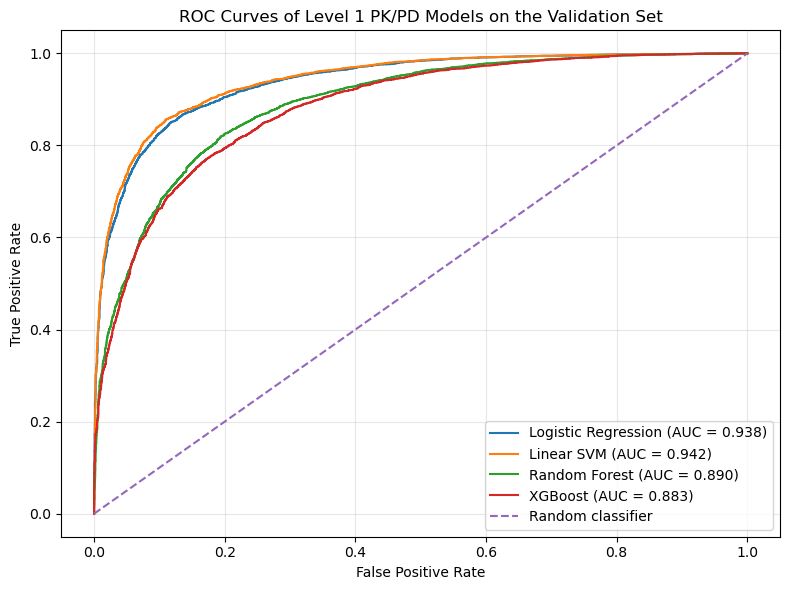

Saved:
- Level1_ROC_Curves_Validation.png
- Level1_ROC_Curves_Validation.pdf
- Level1_ROC_Curve_Data_Validation.csv


In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import joblib

X_validation = sparse.load_npz(
    data_dir / "Level1_Morgan_Validation.npz"
).tocsr()

y_validation = np.load(
    data_dir / "Level1_y_validation.npy"
).astype(np.int8)

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Linear SVM": "linear_svm.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost.joblib"
}

roc_rows = []

plt.figure(figsize=(8, 6))

for model_name, file_name in model_files.items():

    model = joblib.load(
        output_dir / file_name
    )

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_validation)[:, 1]
    else:
        scores = model.decision_function(X_validation)

    fpr, tpr, thresholds = roc_curve(
        y_validation,
        scores
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

    for i in range(len(fpr)):
        roc_rows.append({
            "Model": model_name,
            "FPR": fpr[i],
            "TPR": tpr[i],
            "Threshold": thresholds[i],
            "AUC": roc_auc
        })

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves of Level 1 PK/PD Models on the Validation Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    data_dir / "Level1_ROC_Curves_Validation.png",
    dpi=300
)

plt.savefig(
    data_dir / "Level1_ROC_Curves_Validation.pdf"
)

plt.show()

roc_df = pd.DataFrame(roc_rows)

roc_df.to_csv(
    data_dir / "Level1_ROC_Curve_Data_Validation.csv",
    index=False
)

print("Saved:")
print("- Level1_ROC_Curves_Validation.png")
print("- Level1_ROC_Curves_Validation.pdf")
print("- Level1_ROC_Curve_Data_Validation.csv")

In [1]:
from pathlib import Path

for f in sorted(Path.cwd().glob("*.joblib")):
    print(f.name)

Level1_Final_LinearSVM_Model.joblib


In [3]:
from pathlib import Path
import numpy as np
from scipy import sparse

data_dir = Path.cwd()

X_train = sparse.load_npz(
    data_dir / "Level1_Morgan_Train.npz"
).tocsr()

X_validation = sparse.load_npz(
    data_dir / "Level1_Morgan_Validation.npz"
).tocsr()

y_train = np.load(
    data_dir / "Level1_y_train.npy"
)

y_validation = np.load(
    data_dir / "Level1_y_validation.npy"
)

print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)

X_train: (80000, 4096)
X_validation: (10000, 4096)
y_train: (80000,)
y_validation: (10000,)


In [5]:
from sklearn.svm import LinearSVC
from sklearn.utils import shuffle
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, matthews_corrcoef
import pandas as pd

RANDOM_STATE = 42
N_RANDOM_RUNS = 20

y_random_results = []

for run in range(N_RANDOM_RUNS):

    print("Y-randomization run", run + 1, "of", N_RANDOM_RUNS)

    y_train_random = shuffle(
        y_train,
        random_state=RANDOM_STATE + run
    )

    random_model = LinearSVC(
        C=1.0,
        dual="auto",
        tol=0.001,
        max_iter=3000,
        random_state=RANDOM_STATE
    )

    random_model.fit(
        X_train,
        y_train_random
    )

    random_prediction = random_model.predict(
        X_validation
    )

    random_score = random_model.decision_function(
        X_validation
    )

    y_random_results.append({
        "Run": run + 1,
        "Accuracy": accuracy_score(y_validation, random_prediction),
        "F1_PD": f1_score(y_validation, random_prediction, zero_division=0),
        "ROC_AUC": roc_auc_score(y_validation, random_score),
        "MCC": matthews_corrcoef(y_validation, random_prediction)
    })

yrand_df = pd.DataFrame(y_random_results)

yrand_summary = pd.DataFrame({
    "Metric": ["Accuracy", "F1_PD", "ROC_AUC", "MCC"],
    "Randomized_Mean": [
        yrand_df["Accuracy"].mean(),
        yrand_df["F1_PD"].mean(),
        yrand_df["ROC_AUC"].mean(),
        yrand_df["MCC"].mean()
    ],
    "Randomized_SD": [
        yrand_df["Accuracy"].std(),
        yrand_df["F1_PD"].std(),
        yrand_df["ROC_AUC"].std(),
        yrand_df["MCC"].std()
    ]
})

yrand_df.to_csv(
    data_dir / "Level1_YRandomization_20Runs.csv",
    index=False
)

yrand_summary.to_csv(
    data_dir / "Level1_YRandomization_Summary.csv",
    index=False
)

print("\nY-randomization individual runs:")
display(yrand_df)

print("\nY-randomization summary:")
display(yrand_summary)

print("\nSaved:")
print("- Level1_YRandomization_20Runs.csv")
print("- Level1_YRandomization_Summary.csv")

Y-randomization run 1 of 20
Y-randomization run 2 of 20
Y-randomization run 3 of 20
Y-randomization run 4 of 20
Y-randomization run 5 of 20
Y-randomization run 6 of 20
Y-randomization run 7 of 20
Y-randomization run 8 of 20
Y-randomization run 9 of 20
Y-randomization run 10 of 20
Y-randomization run 11 of 20
Y-randomization run 12 of 20
Y-randomization run 13 of 20
Y-randomization run 14 of 20
Y-randomization run 15 of 20
Y-randomization run 16 of 20
Y-randomization run 17 of 20
Y-randomization run 18 of 20
Y-randomization run 19 of 20
Y-randomization run 20 of 20

Y-randomization individual runs:


,Run,Accuracy,F1_PD,ROC_AUC,MCC
0,1,0.5152,0.599140,0.501663,0.001632
1,2,0.5225,0.606445,0.508809,0.016494
2,3,0.5088,0.592027,0.494522,-0.010946
3,4,0.5088,0.593377,0.489288,-0.011717
4,5,0.5232,0.607184,0.522166,0.017902
5,6,0.5219,0.602147,0.511309,0.017220
6,7,0.5084,0.592574,0.492968,-0.012296
7,8,0.5022,0.585443,0.483917,-0.024291
8,9,0.5131,0.597969,0.496746,-0.003156
9,10,0.5215,0.604774,0.508659,0.014813



Y-randomization summary:


,Metric,Randomized_Mean,Randomized_SD
0,Accuracy,0.513935,0.007929
1,F1_PD,0.597711,0.007365
2,ROC_AUC,0.501356,0.010637
3,MCC,-0.000833,0.016476



Saved:
- Level1_YRandomization_20Runs.csv
- Level1_YRandomization_Summary.csv


In [6]:
comparison_final = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "ROC_AUC",
        "MCC"
    ],
    "Original_Model": [
        0.8683,
        0.9418,
        0.7347
    ],
    "Y_Randomization_Mean": [
        0.513935,
        0.501356,
        -0.000833
    ]
})

comparison_final.to_csv(
    "Level1_YRandomization_Final_Comparison.csv",
    index=False
)

display(comparison_final)

print("Saved:")
print("Level1_YRandomization_Final_Comparison.csv")

,Metric,Original_Model,Y_Randomization_Mean
0,Accuracy,0.8683,0.513935
1,ROC_AUC,0.9418,0.501356
2,MCC,0.7347,-0.000833


Saved:
Level1_YRandomization_Final_Comparison.csv


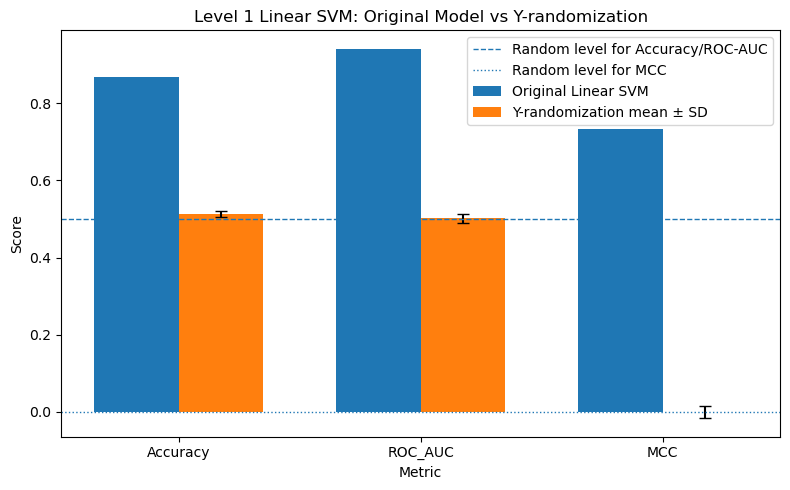

C:\Users\user\AppData\Local\Temp\ipykernel_21776\1685480717.py:109: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


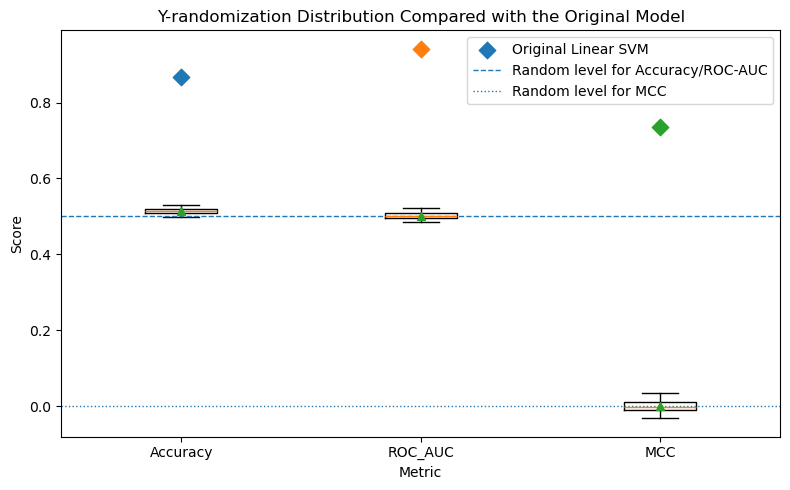

Saved:
- Level1_YRandomization_BarPlot.png
- Level1_YRandomization_BarPlot.pdf
- Level1_YRandomization_BoxPlot.png
- Level1_YRandomization_BoxPlot.pdf


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

data_dir = Path.cwd()

yrand_df = pd.read_csv(
    data_dir / "Level1_YRandomization_20Runs.csv"
)

original_values = {
    "Accuracy": 0.8683,
    "ROC_AUC": 0.9418,
    "MCC": 0.7347
}

metrics = ["Accuracy", "ROC_AUC", "MCC"]

random_means = [
    yrand_df[metric].mean()
    for metric in metrics
]

random_sds = [
    yrand_df[metric].std()
    for metric in metrics
]

original_scores = [
    original_values[metric]
    for metric in metrics
]


# ============================================================
# 1. Bar plot: Original vs Y-randomization mean
# ============================================================

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    original_scores,
    width,
    label="Original Linear SVM"
)

plt.bar(
    x + width / 2,
    random_means,
    width,
    yerr=random_sds,
    capsize=4,
    label="Y-randomization mean ± SD"
)

plt.axhline(
    y=0.5,
    linestyle="--",
    linewidth=1,
    label="Random level for Accuracy/ROC-AUC"
)

plt.axhline(
    y=0.0,
    linestyle=":",
    linewidth=1,
    label="Random level for MCC"
)

plt.xticks(
    x,
    metrics
)

plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Level 1 Linear SVM: Original Model vs Y-randomization")
plt.legend()
plt.tight_layout()

plt.savefig(
    data_dir / "Level1_YRandomization_BarPlot.png",
    dpi=300
)

plt.savefig(
    data_dir / "Level1_YRandomization_BarPlot.pdf"
)

plt.show()


# ============================================================
# 2. Box plot: distribution of randomized runs
# ============================================================

box_data = [
    yrand_df[metric].values
    for metric in metrics
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    box_data,
    labels=metrics,
    showmeans=True
)

for i, metric in enumerate(metrics, start=1):
    plt.scatter(
        i,
        original_values[metric],
        marker="D",
        s=70,
        label="Original Linear SVM" if i == 1 else None
    )

plt.axhline(
    y=0.5,
    linestyle="--",
    linewidth=1,
    label="Random level for Accuracy/ROC-AUC"
)

plt.axhline(
    y=0.0,
    linestyle=":",
    linewidth=1,
    label="Random level for MCC"
)

plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Y-randomization Distribution Compared with the Original Model")
plt.legend()
plt.tight_layout()

plt.savefig(
    data_dir / "Level1_YRandomization_BoxPlot.png",
    dpi=300
)

plt.savefig(
    data_dir / "Level1_YRandomization_BoxPlot.pdf"
)

plt.show()


print("Saved:")
print("- Level1_YRandomization_BarPlot.png")
print("- Level1_YRandomization_BarPlot.pdf")
print("- Level1_YRandomization_BoxPlot.png")
print("- Level1_YRandomization_BoxPlot.pdf")

In [9]:
from pathlib import Path

data_dir = Path.cwd()

for f in sorted(data_dir.glob("*Level2*")):
    print(f.name)

Level2_Classification_Report.csv
Level2_LabelEncoder.pkl
Level2_Metrics.csv
Level2_Validation_Summary.csv
Level2_XGB_Model_min100_sample1000.pkl


In [10]:
import pandas as pd

metrics = pd.read_csv("Level2_Metrics.csv")

print(metrics)

              Metric     Value
0           Accuracy  0.926096
1  Balanced Accuracy  0.944830
2           Macro F1  0.939766
3        Weighted F1  0.923804
4     Top-3 Accuracy  0.984327


In [11]:
import joblib

label_encoder = joblib.load("Level2_LabelEncoder.pkl")

print("Number of Level 2 classes:", len(label_encoder.classes_))

print("\nFirst 20 classes:")
for c in label_encoder.classes_[:20]:
    print("-", c)

Number of Level 2 classes: 61

First 20 classes:
- 2
- 3
- 5
- 6
- 10
- 11
- 12
- 13
- 14
- 15
- 17
- 19
- 20
- 21
- 22
- 27
- 29
- 30
- 33
- 34


In [14]:
from pathlib import Path

data_dir = Path.cwd()

for f in sorted(data_dir.glob("*Level2*")):
    print(f.name)

print("\nOther possible X/y files:")
for f in sorted(data_dir.glob("*test*")):
    print(f.name)

for f in sorted(data_dir.glob("*train*")):
    print(f.name)

Level2_Classification_Report.csv
Level2_LabelEncoder.pkl
Level2_Metrics.csv
Level2_Validation_Summary.csv
Level2_XGB_Model_min100_sample1000.pkl
X_test_Level2.npy
y_pred_Level2.npy
y_proba_Level2.npy
y_test_Level2.npy

Other possible X/y files:
Level1_Final_Test_Confusion_Matrix.csv
Level1_Final_Test_Pairs.csv
Level1_Final_Test_Predictions.csv
Level1_Final_Test_Results.csv
Level1_Morgan_Final_Test.npz
Level1_y_final_test.npy
X_test_Level2.npy
y_test_Level2.npy
Level1_Morgan_Train.npz
Level1_Train_Pairs.csv
Level1_y_train.npy
Xatc_train.npy


In [15]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

data_dir = Path.cwd()

X_train_l2 = np.load(data_dir / "Xact_train.npy")
y_train_l2 = np.load(data_dir / "yact_train.npy")

X_test_l2 = np.load(data_dir / "X_test_Level2.npy")
y_test_l2 = np.load(data_dir / "y_test_Level2.npy")

label_encoder_l2 = joblib.load(data_dir / "Level2_LabelEncoder.pkl")

print("X_train_l2:", X_train_l2.shape)
print("y_train_l2:", y_train_l2.shape)
print("X_test_l2:", X_test_l2.shape)
print("y_test_l2:", y_test_l2.shape)
print("Number of classes:", len(label_encoder_l2.classes_))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\user\\Desktop\\drug drug\\drug2\\Xact_train.npy'

In [16]:
from pathlib import Path

for f in sorted(Path.cwd().glob("*.npy")):
    print(f.name)

Level1_y_final_test.npy
Level1_y_train.npy
Level1_y_validation.npy
X_test_Level2.npy
Xatc_train.npy
y_pred_Level2.npy
y_proba_Level2.npy
y_test_Level2.npy


In [17]:
import numpy as np

X_train_l2 = np.load("Xatc_train.npy")
y_train_l2 = np.load("yatc_train.npy")

X_test_l2 = np.load("X_test_Level2.npy")
y_test_l2 = np.load("y_test_Level2.npy")

print("X_train:", X_train_l2.shape)
print("y_train:", y_train_l2.shape)

print("X_test:", X_test_l2.shape)
print("y_test:", y_test_l2.shape)

print("Classes:", len(np.unique(y_train_l2)))

X_train: (16000, 4107)
y_train: (16000,)
X_test: (7848, 4107)
y_test: (7848,)
Classes: 2


In [18]:
import numpy as np
from pathlib import Path

for f in sorted(Path.cwd().glob("*.npy")):
    try:
        arr = np.load(f)
        print(f.name, arr.shape, "unique:", len(np.unique(arr)) if arr.ndim == 1 else "-")
    except:
        print(f.name, "could not load")

Level1_y_final_test.npy (10000,) unique: 2
Level1_y_train.npy (80000,) unique: 2
Level1_y_validation.npy (10000,) unique: 2
X_test_Level2.npy (7848, 4107) unique: -
Xatc_train.npy (16000, 4107) unique: -
y_pred_Level2.npy (7848,) unique: 61
y_proba_Level2.npy (7848, 61) unique: -
y_test_Level2.npy (7848,) unique: 61
yatc_train.npy (16000,) unique: 2


In [19]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

data_dir = Path.cwd()

print("Current folder:", data_dir)

for f in sorted(data_dir.glob("*.npy")):
    arr = np.load(f)
    if arr.ndim == 1:
        print(f.name, arr.shape, "unique =", len(np.unique(arr)))
    else:
        print(f.name, arr.shape)

Current folder: C:\Users\user\Desktop\drug drug\drug2
Level1_y_final_test.npy (10000,) unique = 2
Level1_y_train.npy (80000,) unique = 2
Level1_y_validation.npy (10000,) unique = 2
X_test_Level2.npy (7848, 4107)
Xatc_train.npy (16000, 4107)
y_pred_Level2.npy (7848,) unique = 61
y_proba_Level2.npy (7848, 61)
y_test_Level2.npy (7848,) unique = 61
yatc_train.npy (16000,) unique = 2


In [20]:
from pathlib import Path

for f in sorted(Path(r"C:\Users\user\Desktop\drug drug").glob("*.npy")):
    print(f.name)

X_enzyme.npy
X_test_Level1.npy
X_test_Level2.npy
Xatc_test.npy
Xatc_train.npy
Xe_test.npy
y_pred_Level1.npy
y_pred_Level2.npy
y_proba_Level1.npy
y_proba_Level2.npy
y_test_Level1.npy
y_test_Level2.npy
yatc_test.npy
yatc_train.npy
ye_pred.npy
ye_proba.npy
ye_test.npy
